# MEC 568: Earth-to-Moon trajectory calculation
## Common Tasks 1–8, followed by Task 9 / Scenario A: Apollo 11

This notebook explains and runs each part of the project in order. It contains **all the code it needs**; the earlier `.py` files are not required.

**How to use it**
1. Open this file in JupyterLab, Jupyter Notebook, VS Code, or Google Colab.
2. Select a Python 3 kernel and choose **Restart Kernel and Run All Cells**.
3. Read the explanation before each task, then inspect its code and output.

The default run takes approximately 30–90 seconds depending on the computer. The numerical solver checks its own verification results. Plots appear inside the notebook and are also saved with CSV/JSON data in `mec568_notebook_results/` under the current working directory.

The handout's Scenario A is **Apollo 11 lunar orbit insertion**. The common baseline stops at the lunar encounter. Only Task 9 adds the lunar capture burn. This is an idealized design, not a reconstruction of a historical mission.

**Navigation:** Setup → Task 1: physics → Task 2: inputs → Task 3: frames → Task 4: integration → Task 5: TLI/coast → Task 6: plots → Task 7: verification → Task 8: sensitivity → Task 9: Scenario A → summary.


### Setup and dependencies
The calculation uses NumPy, SciPy, and Matplotlib. IPython's display helpers are provided by a normal Jupyter installation. If any scientific package is missing, uncomment and run the installation line below once, then restart the kernel.


In [1]:
# Optional, only if dependencies are missing:
# %pip install numpy scipy matplotlib


In [2]:
from dataclasses import dataclass, asdict
from pathlib import Path
import csv
import json
import platform
import time

import numpy as np
import scipy
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicHermiteSpline
from scipy.optimize import brentq, least_squares
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

OUTPUT = Path.cwd() / 'mec568_notebook_results'
OUTPUT.mkdir(parents=True, exist_ok=True)
run_started = time.perf_counter()


def display_table(rows):
    """Render small result tables without requiring pandas."""
    if not rows:
        return
    columns = list(rows[0])
    def cell(value):
        if value is None:
            return '-'
        if isinstance(value, (float, np.floating)):
            return f'{value:.9g}'
        return str(value).replace('|', '/')
    lines = ['| ' + ' | '.join(columns) + ' |',
             '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    lines += ['| ' + ' | '.join(cell(row.get(key)) for key in columns) + ' |'
              for row in rows]
    display(Markdown('\n'.join(lines)))


def show_figures(*filenames):
    """Display the computed images; no external image downloads are used."""
    for filename in filenames:
        display(Image(filename=str(OUTPUT / filename), width=850))


print(f'Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}')
print(f'Numerical output folder: {OUTPUT}')


Python 3.15.0, NumPy 2.5.4, SciPy 1.18.1
Numerical output folder: c:\Users\ruthv\Documents\MEC568-Project\mec568_notebook_results


### Constants and editable settings
The gravitational parameters, radii, and Earth–Moon distance below follow Section 4.5 of the handout. The lunar mean motion is computed consistently from those constants:

\[
n=\sqrt{\frac{\mu_E+\mu_M}{a^3}}.
\]

Our chosen design targets are **110 km lunar altitude** and **72 hours from TLI to the encounter**. The mass and specific impulse values are explicitly assumed for rocket-equation bookkeeping; they are not a historical Saturn/Apollo propulsion model. Change the settings here, then rerun all following cells. Large changes can require different targeting guesses/bounds.


In [3]:
# Required common constants. Compute the mean motion rather than rounding it.
MU_EARTH = 398600.4418       # km^3/s^2
MU_MOON = 4902.800          # km^3/s^2
R_EARTH = 6378.137          # km
R_MOON = 1737.4            # km
MOON_ORBIT_RADIUS = 384400.0  # km
MEAN_MOTION = np.sqrt((MU_EARTH + MU_MOON) / MOON_ORBIT_RADIUS**3)
MASS_RATIO = MU_MOON / (MU_EARTH + MU_MOON)
G0 = 9.80665               # m/s^2, used only in the rocket equation
HOUR = 3600.0
DAY = 86400.0


@dataclass(frozen=True)
class Settings:
    """Editable choices, separated from fixed physical constants.

    The handout permits an impulsive TLI. That is the model used here.
    The 72 h arrival target is our design choice, not a historical Apollo epoch.
    Mass/Isp inputs are illustrative propulsion assumptions. They do not claim
    to reconstruct the masses or performance of a flown Saturn/Apollo stage.
    """
    parking_altitude_km: float = 185.0
    target_lunar_altitude_km: float = 110.0
    target_arrival_time_h: float = 72.0
    mass_before_tli_kg: float = 45000.0
    tli_specific_impulse_s: float = 421.0
    loi_specific_impulse_s: float = 314.0
    captured_orbit_duration_h: float = 24.0

    # Initial guesses for a numerical solve, NOT precomputed final answers.
    tli_guess_m_s: float = 3150.0
    moon_phase_guess_deg: float = 130.0

    reference_rtol: float = 1e-12  # handout requires <= 1e-10
    reference_atol: float = 1e-13
    rk4_step_s: float = 10.0
    convergence_steps_s: tuple = (40.0, 20.0, 10.0, 5.0)
    maximum_coast_days: float = 6.0


settings = Settings()
display_table([{'Input': key, 'Value': value} for key, value in asdict(settings).items()])


| Input | Value |
| --- | --- |
| parking_altitude_km | 185 |
| target_lunar_altitude_km | 110 |
| target_arrival_time_h | 72 |
| mass_before_tli_kg | 45000 |
| tli_specific_impulse_s | 421 |
| loi_specific_impulse_s | 314 |
| captured_orbit_duration_h | 24 |
| tli_guess_m_s | 3150 |
| moon_phase_guess_deg | 130 |
| reference_rtol | 1e-12 |
| reference_atol | 1e-13 |
| rk4_step_s | 10 |
| convergence_steps_s | (40.0, 20.0, 10.0, 5.0) |
| maximum_coast_days | 6 |

## Task 1: theoretical background and governing equations

We use the state
\[
\mathbf y=(x,y,v_x,v_y,m),
\]
with position in km, velocity in km/s, time in s, and mass in kg. The equations are
\[
\dot{\mathbf r}=\mathbf v,\qquad
\dot{\mathbf v}=
-\mu_E\frac{\mathbf r}{\|\mathbf r\|^3}
-\mu_M\left[\frac{\mathbf r-\mathbf r_M}{\|\mathbf r-\mathbf r_M\|^3}
+\frac{\mathbf r_M}{\|\mathbf r_M\|^3}\right]
+\frac{T}{m}\hat{\mathbf u}.
\]

| Symbol | Meaning |
|---|---|
| \(\mathbf r,\mathbf v\) | Earth-relative spacecraft position and velocity |
| \(\mathbf r_M\) | Earth-relative Moon position at the current time |
| \(\mu_E,\mu_M\) | Earth and Moon gravitational parameters, \(GM\) |
| \(T,\hat{\mathbf u}\) | Thrust magnitude and unit direction |
| \(m\) | Spacecraft mass |

The first term is Earth's gravity. The next direct term is the Moon's pull on the spacecraft. The **indirect term** subtracts Earth's acceleration toward the Moon because the origin follows Earth.

For a rocket,
\[
T=\dot m_p V_e,\qquad \frac{dm}{dt}=-\dot m_p,
\qquad V_e=I_{sp}g_0,\qquad
\Delta v=V_e\ln\frac{m_{before}}{m_{after}}.
\]
Here \(\dot m_p>0\) is outgoing propellant flow, \(V_e\) is effective exhaust speed, \(I_{sp}\) is specific impulse in seconds, and \(g_0=9.80665\;\mathrm{m/s^2}\).

**Why use \(m\dot{\mathbf v}=\mathbf F_{gravity}+T\hat{\mathbf u}\)?** A rocket is an open system. Thrust represents the momentum carried away by exhaust. Writing \(d(m\mathbf v)/dt=\mathbf F_{gravity}\) alone leaves out that exhaust momentum flux.

This implementation uses the handout's permitted **impulsive burns**. Between burns, \(T=0\) and mass is constant. The fifth state derivative is therefore zero during a coast. An impulse changes velocity and mass instantaneously, as shown in Task 2.


In [5]:
def coast_derivative(time_s, state, phase_rad, include_moon=True):
    """Task 1: equation (1) during an unpowered coast.

    Earth's direct gravity, Moon's direct gravity, and the indirect term are
    separate below so their physical meanings remain visible. Spacecraft mass
    cancels from gravitational acceleration. It stays in the state for clarity.
    include_moon=False turns off BOTH lunar terms for verification test V1.
    """
    position = state[:2]
    velocity = state[2:4]
    earth_acceleration = -MU_EARTH * position / np.linalg.norm(position)**3
    acceleration = earth_acceleration

    if include_moon:
        moon_position, _ = moon_state(time_s, phase_rad)
        relative_position = position - moon_position
        lunar_direct = -MU_MOON * relative_position / np.linalg.norm(relative_position)**3
        lunar_indirect = -MU_MOON * moon_position / MOON_ORBIT_RADIUS**3
        acceleration = acceleration + lunar_direct + lunar_indirect

    return np.array([velocity[0], velocity[1], acceleration[0], acceleration[1], 0.0])


## Task 2: initial conditions and moving Moon

We start at \(\mathbf r_0=(R_E+185,0)\) km, in a circular prograde parking orbit with
\[
\mathbf v_{parking}=\left(0,\sqrt{\mu_E/\|\mathbf r_0\|}\right).
\]
TLI adds a tangential velocity increment. The mass after an impulse follows
\[
m_{after}=m_{before}\exp\left[-\frac{\|\Delta\mathbf v\|}{I_{sp}g_0}\right].
\]
The code converts \(\Delta v\) from km/s to m/s before using \(g_0\).

The Moon moves throughout the integration:
\[
\mathbf r_M(t)=a\begin{bmatrix}\cos(nt+\theta_0)\\\sin(nt+\theta_0)\end{bmatrix},
\qquad \mathbf v_M(t)=n\begin{bmatrix}-r_{M,y}\\r_{M,x}\end{bmatrix}.
\]

The pre-burn state and assumed initial mass are defined here. The final TLI magnitude and Moon phase \(\theta_0\) are **unknown design variables**. Task 5 solves for them once the numerical integrators are available. The guesses in `settings` are not the final answers.


In [6]:
def moon_state(time_s, phase_rad):
    """Task 2: Moon position and velocity, updated at every ODE stage.

    Supports a scalar time or a 1-D array. Returned vectors have shape (2,)
    for a scalar and (n_times, 2) for an array.
    """
    angle = MEAN_MOTION * np.asarray(time_s) + phase_rad
    position = MOON_ORBIT_RADIUS * np.stack((np.cos(angle), np.sin(angle)), axis=-1)
    velocity = MEAN_MOTION * np.stack((-position[..., 1], position[..., 0]), axis=-1)
    return position, velocity


def parking_state(settings):
    """Task 2: circular 185 km parking orbit BEFORE the departure impulse."""
    radius = R_EARTH + settings.parking_altitude_km
    circular_speed = np.sqrt(MU_EARTH / radius)
    return np.array([radius, 0.0, 0.0, circular_speed, settings.mass_before_tli_kg])


def apply_impulse(state_before, delta_velocity_km_s, specific_impulse_s):
    """Tasks 1-2: instant velocity change and rocket-equation mass decrease.

    Position is continuous. Convert km/s to m/s because G0 is in m/s^2.
    No burn-duration or gravity-loss approximation is hidden in this function.
    """
    delta_velocity = np.asarray(delta_velocity_km_s, dtype=float)
    delta_v_m_s = 1000.0 * np.linalg.norm(delta_velocity)
    state_after = state_before.copy()
    state_after[2:4] += delta_velocity
    state_after[4] *= np.exp(-delta_v_m_s / (specific_impulse_s * G0))
    return state_after


def departure_state(settings, delta_v_m_s):
    """Task 5: single tangential, prograde impulsive TLI from the parking orbit."""
    return apply_impulse(
        parking_state(settings), [0.0, delta_v_m_s / 1000.0],
        settings.tli_specific_impulse_s,
    )

parking = parking_state(settings)
display_table([{'State component': name, 'Before TLI': float(value)}
               for name, value in zip(['x (km)', 'y (km)', 'vx (km/s)', 'vy (km/s)', 'mass (kg)'], parking)])


| State component | Before TLI |
| --- | --- |
| x (km) | 6563.137 |
| y (km) | 0 |
| vx (km/s) | 0 |
| vy (km/s) | 7.79315211 |
| mass (kg) | 45000 |

## Task 3: reference frames and transformations

We integrate the whole flight in one Earth-relative frame. Moon-centered coordinates make the encounter and LOI calculation clear. Rotating barycentric coordinates show the Earth–Moon geometry.

**Moon-centered inertial coordinates, with parallel axes:**
\[
\boldsymbol\rho=\mathbf r-\mathbf r_M,\qquad
\dot{\boldsymbol\rho}=\mathbf v-\mathbf v_M.
\]
Both position **and velocity** must be translated.

For the rotating frame, define \(\alpha=nt+\theta_0\), \(\mu=\mu_M/(\mu_E+\mu_M)\), and
\[
R(-\alpha)=\begin{bmatrix}\cos\alpha&\sin\alpha\\-\sin\alpha&\cos\alpha\end{bmatrix}.
\]
Then
\[
\mathbf q=R(-\alpha)\mathbf r-(\mu a,0),\qquad
\dot{\mathbf q}=R(-\alpha)\mathbf v-\mathbf n\times[R(-\alpha)\mathbf r],
\]
where \(\mathbf n=n\hat{\mathbf z}\) and \(\mathbf n\times(X,Y)=(-nY,nX)\).

The velocity correction comes from differentiating the rotating axes. The inverse transform below checks that we recover the original position and velocity. Task 6 repeats this check over the entire solved coast.

An additional check uses the dimensionless Jacobi constant:
\[
C=X^2+Y^2+\frac{2(1-\mu)}{d_E}+\frac{2\mu}{d_M}-(U^2+V^2),
\]
where \((X,Y)=\mathbf q/a\), \((U,V)=\dot{\mathbf q}/(na)\),
\(d_E=\sqrt{(X+\mu)^2+Y^2}\), and \(d_M=\sqrt{(X-1+\mu)^2+Y^2}\).
It is conserved on an unpowered coast in this circular model, but changes across an impulse. Earth-relative two-body energy is not conserved when the Moon acts.


In [7]:
def to_moon_frame(time_s, earth_state, phase_rad):
    """Task 3: parallel-axis MCI translation, rho=r-rM and v_rel=v-vM."""
    moon_position, moon_velocity = moon_state(time_s, phase_rad)
    return earth_state[..., :2] - moon_position, earth_state[..., 2:4] - moon_velocity


def to_rotating_frame(time_s, earth_state, phase_rad):
    """Task 3: ECI to barycentric Earth-Moon rotating POSITION AND VELOCITY.

    alpha = n*t+phase; R(-alpha) rotates inertial axes into rotating axes.
    q = R*r - (mu*a, 0).
    q_dot = R*v - n cross (R*r).
    The time derivative of the rotation is essential for velocity/Jacobi checks.
    """
    angle = MEAN_MOTION * np.asarray(time_s) + phase_rad
    cosine, sine = np.cos(angle), np.sin(angle)
    position, velocity = earth_state[..., :2], earth_state[..., 2:4]
    rotated_position = np.stack((
        cosine * position[..., 0] + sine * position[..., 1],
        -sine * position[..., 0] + cosine * position[..., 1],
    ), axis=-1)
    rotated_velocity = np.stack((
        cosine * velocity[..., 0] + sine * velocity[..., 1],
        -sine * velocity[..., 0] + cosine * velocity[..., 1],
    ), axis=-1)
    spin_velocity = MEAN_MOTION * np.stack(
        (-rotated_position[..., 1], rotated_position[..., 0]), axis=-1,
    )
    return (rotated_position - np.array([MASS_RATIO * MOON_ORBIT_RADIUS, 0.0]),
            rotated_velocity - spin_velocity)


def from_rotating_frame(time_s, position, velocity, phase_rad):
    """Task 3 verification: invert BOTH the origin shift and velocity transform."""
    earth_relative_rotated = position + np.array([MASS_RATIO * MOON_ORBIT_RADIUS, 0.0])
    spin_velocity = MEAN_MOTION * np.stack(
        (-earth_relative_rotated[..., 1], earth_relative_rotated[..., 0]), axis=-1,
    )
    rotated_inertial_velocity = velocity + spin_velocity
    angle = MEAN_MOTION * np.asarray(time_s) + phase_rad
    cosine, sine = np.cos(angle), np.sin(angle)

    def rotate_back(vector):
        return np.stack((cosine * vector[..., 0] - sine * vector[..., 1],
                         sine * vector[..., 0] + cosine * vector[..., 1]), axis=-1)

    return rotate_back(earth_relative_rotated), rotate_back(rotated_inertial_velocity)


def jacobi_constant(time_s, earth_state, phase_rad):
    """Task 3 accuracy check: dimensionless CR3BP Jacobi C, valid on each coast.

    Length unit=a and velocity unit=n*a. C changes across a powered impulse.
    Earth-centered orbital energy is NOT conserved when the moving Moon acts.
    """
    position, velocity = to_rotating_frame(time_s, earth_state, phase_rad)
    position = position / MOON_ORBIT_RADIUS
    velocity = velocity / (MEAN_MOTION * MOON_ORBIT_RADIUS)
    x, y = position[..., 0], position[..., 1]
    earth_distance = np.sqrt((x + MASS_RATIO)**2 + y**2)
    moon_distance = np.sqrt((x - 1.0 + MASS_RATIO)**2 + y**2)
    return (x*x + y*y + 2.0 * (1.0 - MASS_RATIO) / earth_distance
            + 2.0 * MASS_RATIO / moon_distance - np.sum(velocity**2, axis=-1))


In [8]:
def task_3_reference_frames(initial_state, phase_rad):
    """Task 3: justify frames and verify the complete forward/inverse transform.

    ECI: all propagation uses one consistent Earth-relative force model.
    MCI: translate position AND velocity to measure the encounter and design LOI.
    Rotating barycentric: visualize Earth-Moon geometry with fixed primaries.
    We transform data for analysis; we do not switch ODE force models mid-flight.
    """
    position, velocity = to_rotating_frame(0.0, initial_state, phase_rad)
    recovered_position, recovered_velocity = from_rotating_frame(0.0, position, velocity, phase_rad)
    position_error = float(np.linalg.norm(recovered_position-initial_state[:2]))
    velocity_error = float(np.linalg.norm(recovered_velocity-initial_state[2:4]))
    if position_error > 1e-8 or velocity_error > 1e-10:
        raise RuntimeError('Task 3 frame transformation round trip failed')
    print('Task 3: ECI propagation, MCI encounter/LOI, rotating-frame display.')
    return {'initial_position_roundtrip_error_km': position_error,
            'initial_velocity_roundtrip_error_km_s': velocity_error}

# A preliminary coordinate check using the parking state and phase guess.
# The final departure and complete trajectory are checked after targeting.
preliminary_frame_check = task_3_reference_frames(parking, np.deg2rad(settings.moon_phase_guess_deg))
display_table([preliminary_frame_check])


Task 3: ECI propagation, MCI encounter/LOI, rotating-frame display.


| initial_position_roundtrip_error_km | initial_velocity_roundtrip_error_km_s |
| --- | --- |
| 1.28621974e-12 | 4.4408921e-16 |

## Task 4: own RK4 and an independent reference integrator

Our fixed-step fourth-order Runge–Kutta method computes
\[
\begin{aligned}
\mathbf k_1&=f(t,\mathbf y),\\
\mathbf k_2&=f(t+h/2,\mathbf y+h\mathbf k_1/2),\\
\mathbf k_3&=f(t+h/2,\mathbf y+h\mathbf k_2/2),\\
\mathbf k_4&=f(t+h,\mathbf y+h\mathbf k_3),\\
\mathbf y_{next}&=\mathbf y+\frac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4).
\end{aligned}
\]
Here \(h\) is the step size and \(f\) is the derivative from Task 1. Only the final step may be shortened to reach an exact endpoint.

The reference uses SciPy `solve_ivp(method="DOP853")` with relative tolerance \(10^{-12}\), tighter than the required \(10^{-10}\). The methods share a physical equation, but use different stepping algorithms. The actual agreement test appears in Task 7.

**Events matter:** lunar closest approach has \(\boldsymbol\rho\cdot\dot{\boldsymbol\rho}=0\), crossing from negative to positive. Surface-contact events stop physical trajectories. During intermediate targeting trials only, surface termination can be disabled to keep the residual smooth. The accepted nominal run must pass the physical checks.

RK4 event refinement uses cubic Hermite interpolation with endpoint positions and velocities. Taking the minimum of sampled distances would introduce an additional error and could hide fourth-order convergence.


In [9]:
@dataclass
class Encounter:
    """Reference solution and the first physical event reached during departure."""
    solution: object
    time_s: float
    state: np.ndarray
    altitude_km: float
    event: str


def rk4(derivative, initial_state, start_s, end_s, step_s):
    """Task 4: classical, fixed-step, fourth-order Runge-Kutta, written explicitly.

    Only the final step can be shorter, so the requested final time is exact.
    The method integrates any state vector, including the constant mass state.
    """
    if step_s <= 0 or end_s <= start_s:
        raise ValueError('RK4 requires positive step and end time after start time')
    count = int(np.ceil((end_s - start_s) / step_s))
    times = start_s + step_s * np.arange(count + 1)
    times[-1] = end_s
    states = np.empty((count + 1, len(initial_state)))
    states[0] = initial_state

    for index in range(count):
        time = times[index]
        state = states[index]
        step = times[index + 1] - time
        k1 = derivative(time, state)
        k2 = derivative(time + step/2, state + step*k1/2)
        k3 = derivative(time + step/2, state + step*k2/2)
        k4 = derivative(time + step, state + step*k3)
        states[index + 1] = state + step * (k1 + 2*k2 + 2*k3 + k4) / 6

    return times, states


def reference_coast(settings, initial_state, phase_rad, start_s, end_s, events=None):
    """Task 4: tight-tolerance DOP853 reference, with dense output for events."""
    solution = solve_ivp(
        lambda time, state: coast_derivative(time, state, phase_rad),
        (start_s, end_s), initial_state, method='DOP853',
        rtol=settings.reference_rtol, atol=settings.reference_atol,
        dense_output=True, events=events, max_step=900.0,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    return solution


def integrate_to_encounter(settings, delta_v_m_s, phase_rad, targeting_trial=False):
    """Tasks 5,8: departure coast ending at lunar periapsis OR surface impact.

    Physical baseline/sensitivity runs stop at a surface. An impact's minimum
    physical altitude is zero; we do not report a fictitious underground flyby.
    During numerical targeting ONLY, surface termination can be disabled to
    keep the optimization residual smooth. Accepted final runs must be physical.
    """
    def closest_approach(time, state):
        position, velocity = to_moon_frame(time, state, phase_rad)
        return np.dot(position, velocity)

    def moon_surface(time, state):
        position, _ = to_moon_frame(time, state, phase_rad)
        return np.linalg.norm(position) - R_MOON

    def earth_surface(time, state):
        return np.linalg.norm(state[:2]) - R_EARTH

    closest_approach.direction = 1
    closest_approach.terminal = True
    moon_surface.direction = -1
    moon_surface.terminal = True
    earth_surface.direction = -1
    earth_surface.terminal = True
    events = [closest_approach] if targeting_trial else [closest_approach, moon_surface, earth_surface]

    solution = reference_coast(
        settings, departure_state(settings, delta_v_m_s), phase_rad,
        0.0, settings.maximum_coast_days * DAY, events,
    )
    found = [(times[0], index) for index, times in enumerate(solution.t_events) if len(times)]
    if not found:
        raise RuntimeError('No lunar encounter or impact within the coast time limit')
    time, event_index = min(found)
    state = solution.sol(time)
    relative_position, _ = to_moon_frame(time, state, phase_rad)
    altitude = float(np.linalg.norm(relative_position) - R_MOON)
    event_name = ['closest_approach', 'moon_impact', 'earth_impact'][event_index]
    if event_name == 'moon_impact':
        altitude = 0.0  # remove numerical root noise at surface contact
    return Encounter(solution, float(time), state, altitude, event_name)


def rk4_lunar_minimum(times, states, phase_rad, expected_time_s):
    """Task 7: event refinement between RK4 steps, preserving fourth-order accuracy.

    Interpolate POSITION using endpoint positions and velocities. Its derivative
    supplies velocity consistently. A sampled distance minimum would add O(h^2)
    error and can obscure the expected RK4 convergence order.
    """
    position_spline = CubicHermiteSpline(times, states[:, :2], states[:, 2:4])

    def radial_product(time):
        moon_position, moon_velocity = moon_state(time, phase_rad)
        position = position_spline(time) - moon_position
        velocity = position_spline(time, 1) - moon_velocity
        return np.dot(position, velocity)

    index = np.searchsorted(times, expected_time_s)
    lower = times[max(0, index - 8)]
    upper = times[min(len(times) - 1, index + 8)]
    time = brentq(radial_product, lower, upper, xtol=1e-7)
    moon_position, _ = moon_state(time, phase_rad)
    altitude = np.linalg.norm(position_spline(time) - moon_position) - R_MOON
    return float(time), float(altitude)


In [10]:
def task_4_numerical_method(settings):
    """Task 4: own RK4 in rk4(); tight independent DOP853 reference.

    The actual numerical comparison is Task 7 / V2-V3, after a coast exists.
    Using a library interpolator for event refinement does not replace RK4.
    """
    if settings.reference_rtol > 1e-10:
        raise ValueError('Reference relative tolerance violates the handout')
    print(f'Task 4: own RK4 h={settings.rk4_step_s:g} s; DOP853 rtol={settings.reference_rtol:g}.')

task_4_numerical_method(settings)


Task 4: own RK4 h=10 s; DOP853 rtol=1e-12.


## Task 5: one TLI impulse and the unpowered translunar coast

We now determine the two unknown departure quantities, \(\Delta v_{TLI}\) and \(\theta_0\). A shooting solve repeatedly propagates a trial departure and adjusts those quantities until the altitude and arrival-time targets match:
\[
\mathbf F(\Delta v_{TLI},\theta_0)=
\begin{bmatrix}
(h_{Moon}-110\;\mathrm{km})/(1000\;\mathrm{km})\\
(t_{arrival}-72\;\mathrm h)/(1\;\mathrm h)
\end{bmatrix}=\mathbf0.
\]
Scaling keeps the two residuals numerically comparable. The solve is not a search for minimum fuel; it satisfies these chosen design targets.

The final physical baseline is propagated separately with surface-contact termination enabled. It ends at lunar closest approach **before any LOI burn**. Its 110 km altitude is inside the baseline's required 100–10,000 km range. Time is measured since TLI, not since launch.


In [11]:
def task_2_initial_conditions(settings):
    """Task 2: define the parking state, mass, departure impulse, and lunar phase.

    A two-variable shooting solve determines delta-v and phase to satisfy our
    chosen 110 km arrival and 72 h coast. Those are design targets, not copied
    mission values. Numerical work here uses the Task 4 functions defined above.
    The physical baseline is subsequently propagated separately in Task 5.
    """
    def residual(parameters):
        delta_v_m_s, phase_deg = parameters
        encounter = integrate_to_encounter(
            settings, delta_v_m_s, np.deg2rad(phase_deg), targeting_trial=True,
        )
        # Scaling gives both residuals comparable influence on the root solve.
        altitude_residual = (encounter.altitude_km-settings.target_lunar_altitude_km)/1000
        time_residual = encounter.time_s/HOUR-settings.target_arrival_time_h
        return np.array([altitude_residual, time_residual])

    fit = least_squares(
        residual, [settings.tli_guess_m_s, settings.moon_phase_guess_deg],
        bounds=([3100.0, 100.0], [3300.0, 170.0]), x_scale=[10.0, 1.0],
        diff_step=1e-5, xtol=1e-11, ftol=1e-11, gtol=1e-10, max_nfev=100,
    )
    errors = residual(fit.x)
    if not fit.success or abs(errors[0])*1000 > 0.01 or abs(errors[1])*HOUR > 0.1:
        raise RuntimeError(f'TLI targeting failed: {fit.message}, residuals={errors}')

    delta_v_m_s, phase_deg = map(float, fit.x)
    phase_rad = float(np.deg2rad(phase_deg))
    before = parking_state(settings)
    after = departure_state(settings, delta_v_m_s)
    result = {
        'parking_altitude_km': settings.parking_altitude_km,
        'parking_state_before_TLI': before.tolist(),
        'state_immediately_after_TLI': after.tolist(),
        'state_columns': ['x_km', 'y_km', 'vx_km_s', 'vy_km_s', 'mass_kg'],
        'TLI_delta_v_m_s': delta_v_m_s,
        'moon_phase_deg': phase_deg,
        'TLI_propellant_kg': float(before[4]-after[4]),
        'propulsion_inputs_are_illustrative_assumptions': True,
    }
    print(f'Task 2: TLI={delta_v_m_s:.6f} m/s, lunar phase={phase_deg:.6f} deg')
    return delta_v_m_s, phase_rad, after, result


def task_5_baseline(settings, delta_v_m_s, phase_rad):
    """Task 5: single impulsive TLI followed by UNPOWERED coast to the Moon.

    This baseline ends immediately before lunar orbit insertion. It satisfies
    Tasks 1-8 independently of the subsequent Scenario A capture maneuver.
    """
    encounter = integrate_to_encounter(settings, delta_v_m_s, phase_rad)
    if encounter.event != 'closest_approach':
        raise RuntimeError(f'Nominal baseline hit a surface: {encounter.event}')
    if not 100.0 <= encounter.altitude_km <= 10000.0:
        raise RuntimeError('Baseline lunar altitude is outside the required 100-10000 km')
    print(f'Task 5: lunar altitude={encounter.altitude_km:.6f} km, TOF={encounter.time_s/HOUR:.6f} h.')
    return encounter

delta_v_m_s, phase_rad, initial_state, initial_summary = task_2_initial_conditions(settings)
frame_checks = task_3_reference_frames(initial_state, phase_rad)
baseline = task_5_baseline(settings, delta_v_m_s, phase_rad)

display_table([
    {'Quantity': 'TLI delta-v', 'Value': delta_v_m_s, 'Unit': 'm/s'},
    {'Quantity': 'Initial lunar phase', 'Value': np.rad2deg(phase_rad), 'Unit': 'deg'},
    {'Quantity': 'Lunar closest-approach altitude', 'Value': baseline.altitude_km, 'Unit': 'km'},
    {'Quantity': 'Time to closest approach', 'Value': baseline.time_s/HOUR, 'Unit': 'h'},
    {'Quantity': 'TLI propellant (assumed mass/Isp)', 'Value': initial_summary['TLI_propellant_kg'], 'Unit': 'kg'},
])
display_table([{'State component': name, 'Before TLI': float(before), 'After TLI': float(after)}
    for name, before, after in zip(['x (km)', 'y (km)', 'vx (km/s)', 'vy (km/s)', 'mass (kg)'],
                                   parking, initial_state)])


Task 2: TLI=3156.241909 m/s, lunar phase=131.448848 deg
Task 3: ECI propagation, MCI encounter/LOI, rotating-frame display.
Task 5: lunar altitude=110.000000 km, TOF=72.000000 h.


| Quantity | Value | Unit |
| --- | --- | --- |
| TLI delta-v | 3156.24191 | m/s |
| Initial lunar phase | 131.448848 | deg |
| Lunar closest-approach altitude | 110 | km |
| Time to closest approach | 72 | h |
| TLI propellant (assumed mass/Isp) | 24049.1325 | kg |

| State component | Before TLI | After TLI |
| --- | --- | --- |
| x (km) | 6563.137 | 6563.137 |
| y (km) | 0 | 0 |
| vx (km/s) | 0 | 0 |
| vy (km/s) | 7.79315211 | 10.949394 |
| mass (kg) | 45000 | 20950.8675 |

## Task 6: trajectories and time histories

The following figures reproduce Section 5.5(a)–(d):

- **ECI trajectory:** includes the Moon's orbit and its position at closest approach.
- **Rotating trajectory:** Earth and Moon stay fixed in the display.
- **Distances:** Earth surface altitude and Moon center distance are different quantities and are labeled separately.
- **ECI speed and mass:** the spacecraft slows as it climbs out of Earth's gravity well. Coast mass remains constant after the instantaneous TLI.

These plots use the tight reference trajectory. Own RK4 independently checks the same lunar arrival in Task 7. A resolved mass-versus-burn-time history is required only for a finite burn; this project uses impulses.

The code also saves the baseline time history and checks frame inversion and Jacobi conservation over the full coast.


Task 6: ECI, rotating, distance, speed/mass plots and trajectory CSV saved.


| initial_position_roundtrip_error_km | initial_velocity_roundtrip_error_km_s | full_coast_position_roundtrip_error_km | full_coast_velocity_roundtrip_error_km_s | maximum_absolute_Jacobi_drift |
| --- | --- | --- | --- | --- |
| 1.28621974e-12 | 0 | 1.21967275e-10 | 1.98602732e-15 | 1.21346488e-10 |

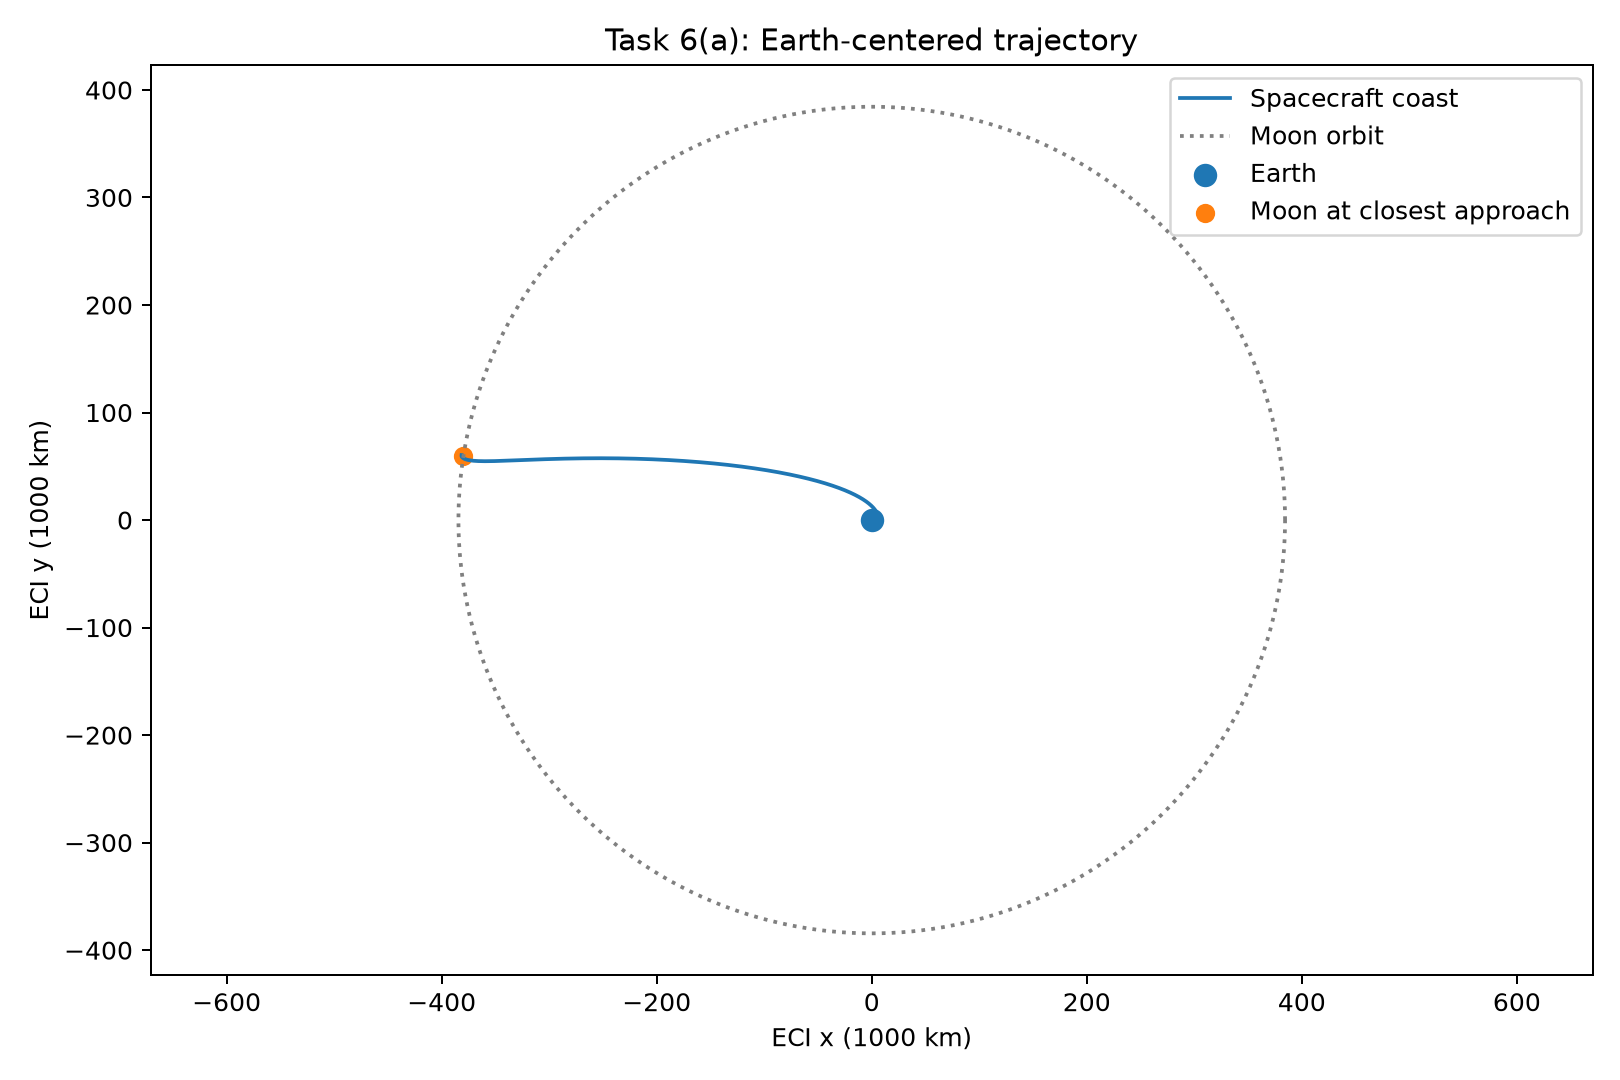

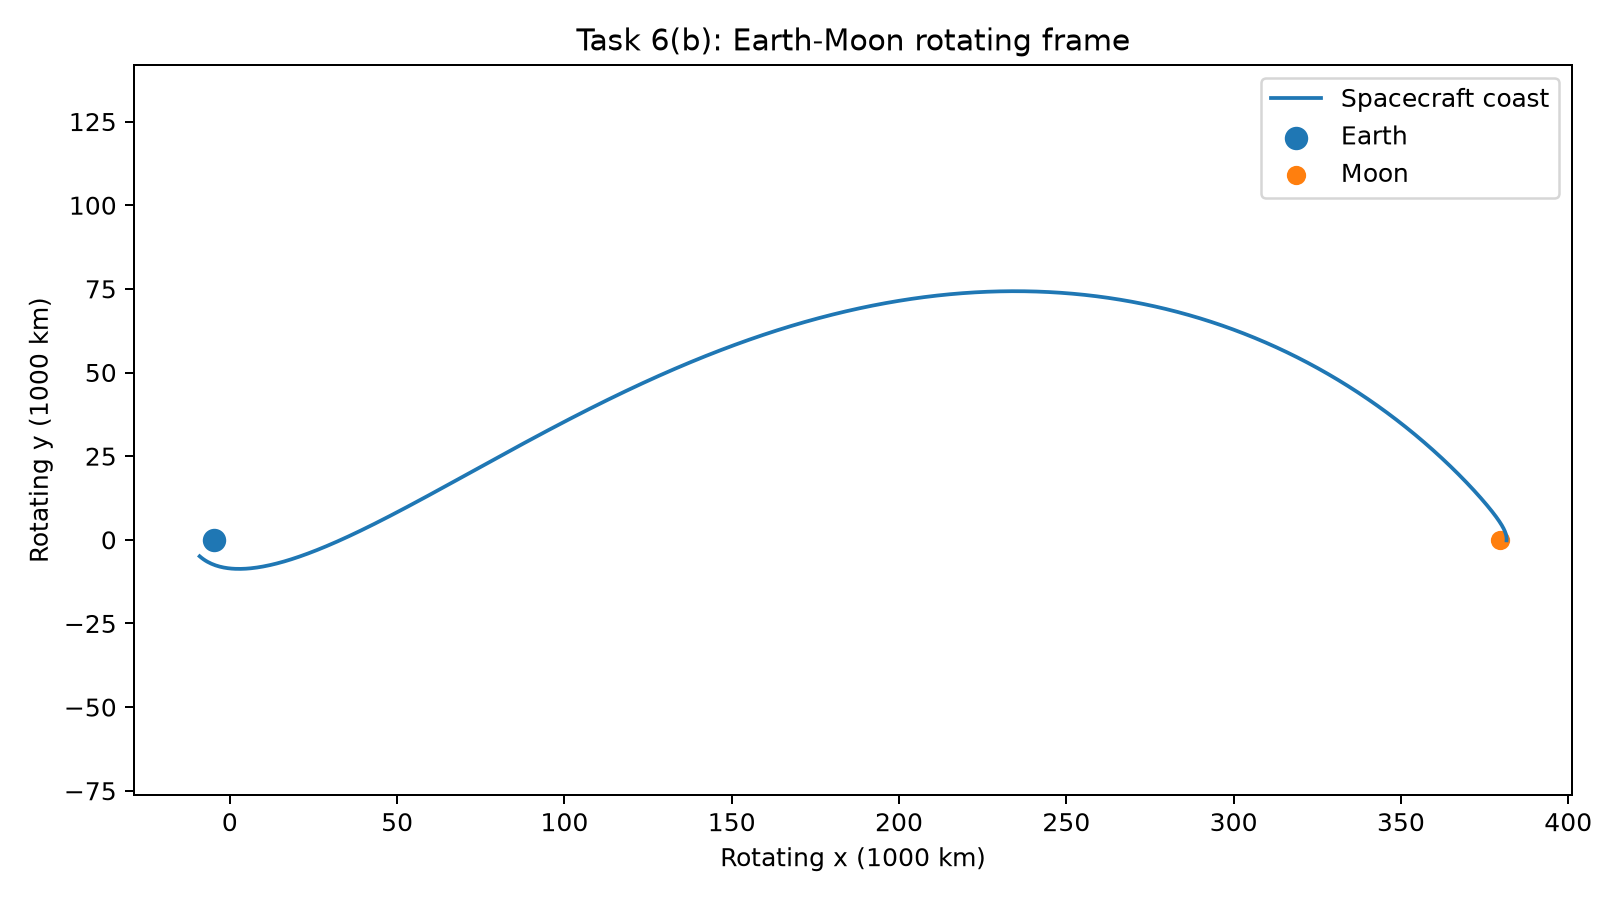

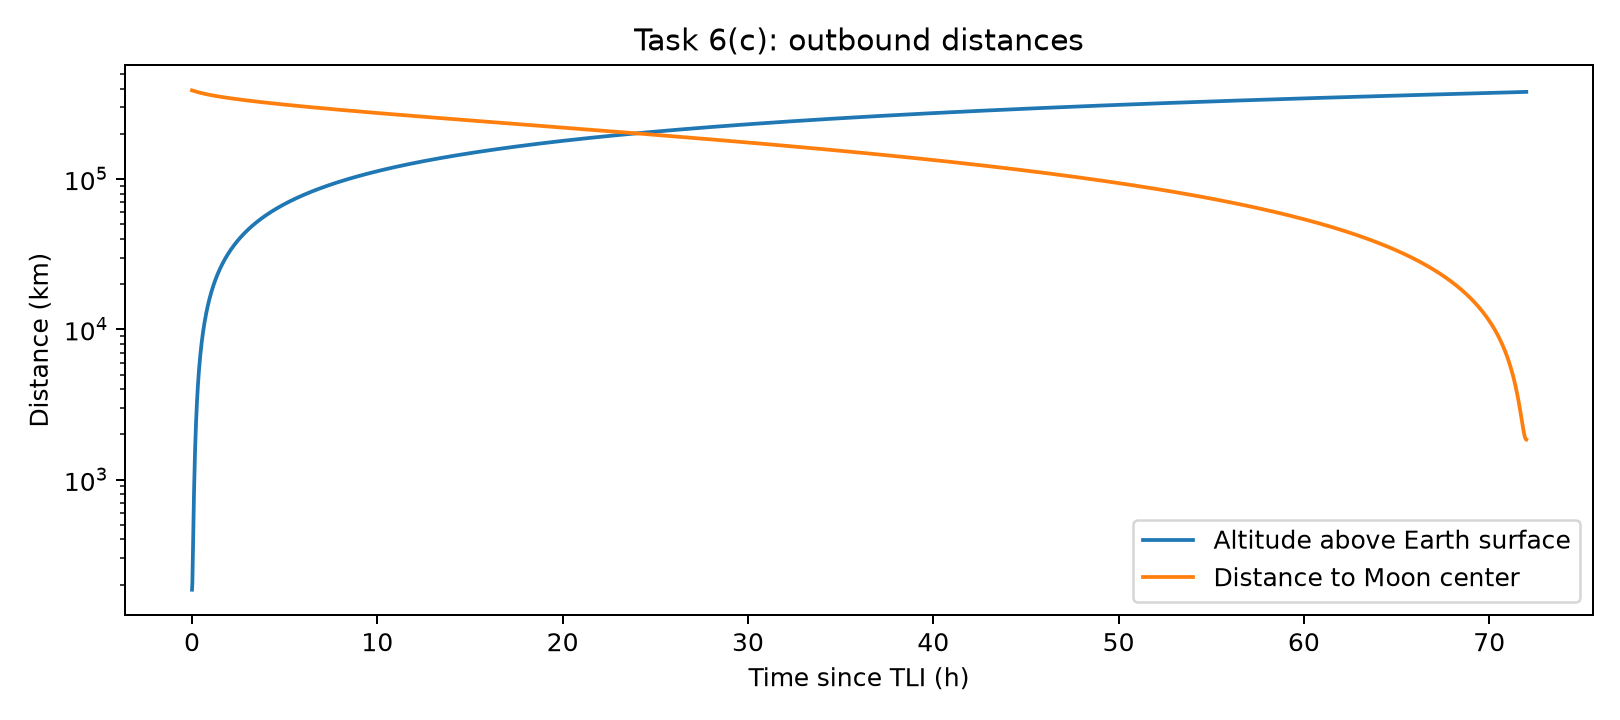

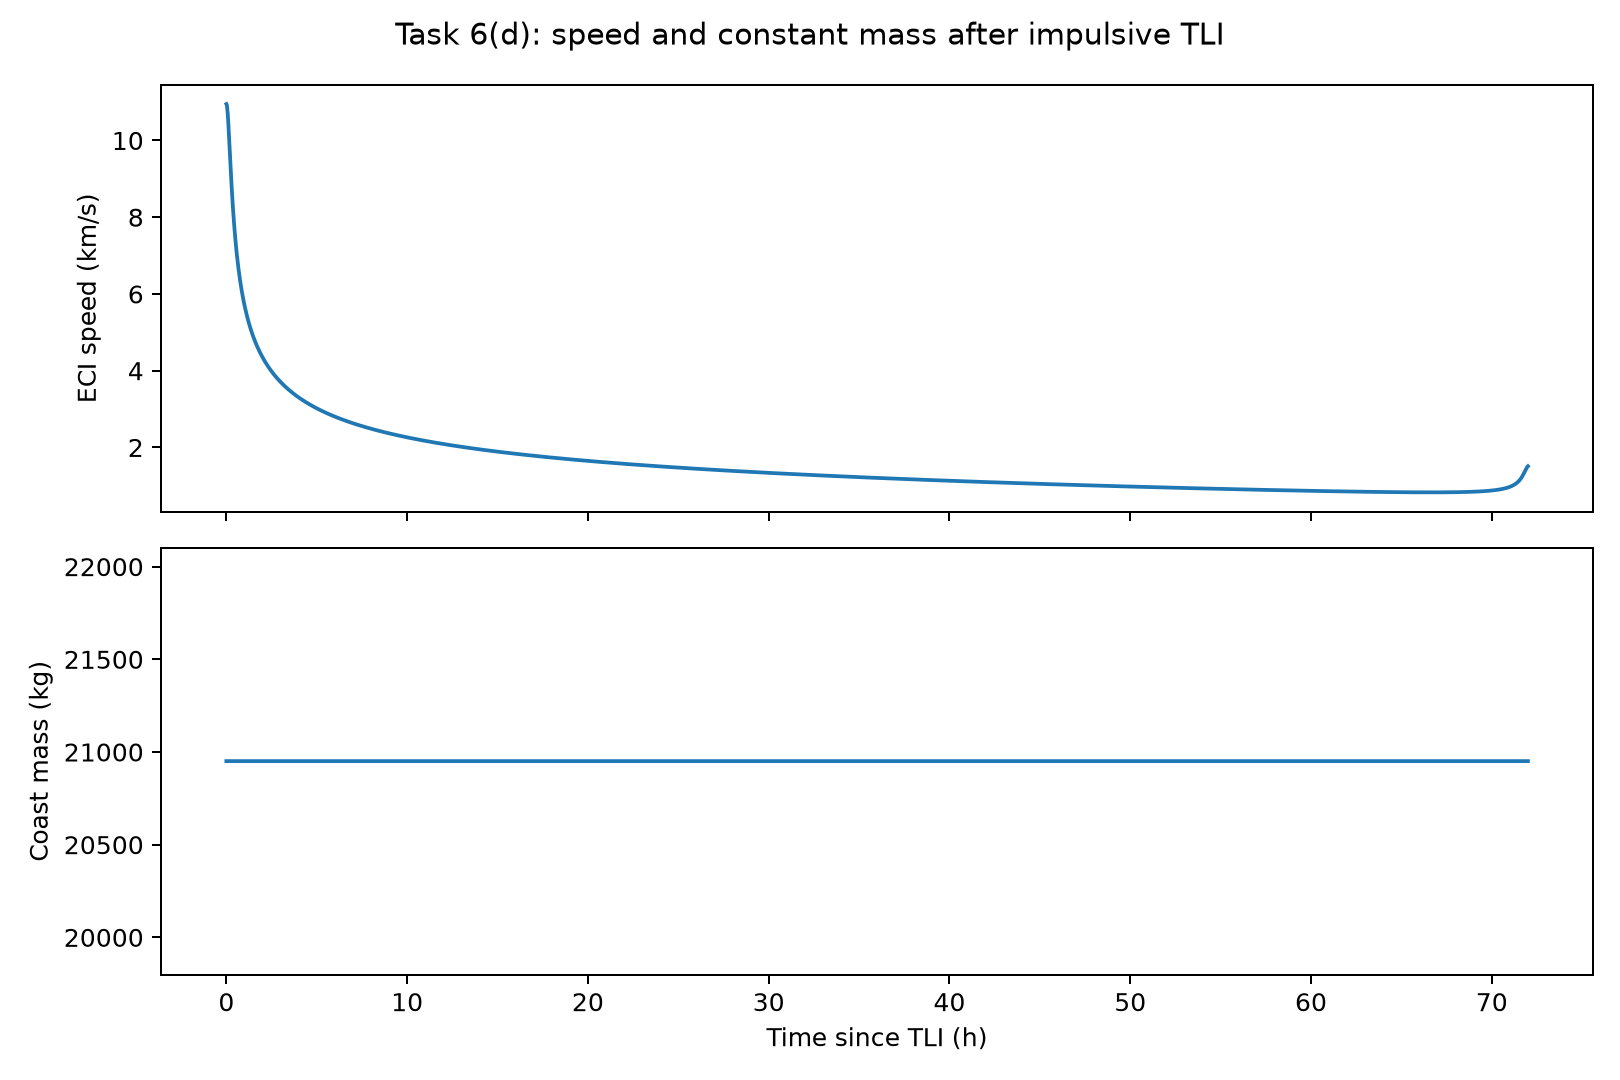

In [12]:
def write_csv(path, rows):
    """Small output helper: write named columns, not unlabeled numeric arrays."""
    with path.open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def save_figure(figure, directory, name):
    figure.tight_layout()
    figure.savefig(directory / name, dpi=180)
    plt.close(figure)


def baseline_figures(directory, encounter, phase_rad):
    """Task 6: required figures (a)-(d), including the moving Moon at arrival."""
    times = np.linspace(0.0, encounter.time_s, 4000)
    states = encounter.solution.sol(times).T
    moon_positions, _ = moon_state(times, phase_rad)
    moon_at_arrival, _ = moon_state(encounter.time_s, phase_rad)

    # Figure (a): ECI trajectory with lunar orbit and Moon's ARRIVAL position.
    figure, axis = plt.subplots(figsize=(9, 6))
    orbit_angle = np.linspace(0, 2*np.pi, 500)
    axis.plot(states[:, 0]/1000, states[:, 1]/1000, label='Spacecraft coast')
    axis.plot(MOON_ORBIT_RADIUS*np.cos(orbit_angle)/1000,
              MOON_ORBIT_RADIUS*np.sin(orbit_angle)/1000, ':', color='gray', label='Moon orbit')
    axis.scatter(0, 0, s=70, label='Earth')
    axis.scatter(*moon_at_arrival/1000, s=45, label='Moon at closest approach')
    axis.set(xlabel='ECI x (1000 km)', ylabel='ECI y (1000 km)', title='Task 6(a): Earth-centered trajectory')
    axis.axis('equal')
    axis.legend()
    save_figure(figure, directory, 'task6a_eci_trajectory.png')

    # Figure (b): barycentric rotating coordinates, with both primaries fixed.
    position, _ = to_rotating_frame(times, states, phase_rad)
    figure, axis = plt.subplots(figsize=(9, 5))
    axis.plot(position[:, 0]/1000, position[:, 1]/1000, label='Spacecraft coast')
    axis.scatter(-MASS_RATIO*MOON_ORBIT_RADIUS/1000, 0, s=70, label='Earth')
    axis.scatter((1-MASS_RATIO)*MOON_ORBIT_RADIUS/1000, 0, s=45, label='Moon')
    axis.set(xlabel='Rotating x (1000 km)', ylabel='Rotating y (1000 km)', title='Task 6(b): Earth-Moon rotating frame')
    axis.axis('equal')
    axis.legend()
    save_figure(figure, directory, 'task6b_rotating_trajectory.png')

    # Figure (c): distinguish EARTH ALTITUDE from MOON CENTER DISTANCE.
    figure, axis = plt.subplots(figsize=(9, 4))
    axis.semilogy(times/HOUR, np.linalg.norm(states[:, :2], axis=1)-R_EARTH,
                  label='Altitude above Earth surface')
    axis.semilogy(times/HOUR, np.linalg.norm(states[:, :2]-moon_positions, axis=1),
                  label='Distance to Moon center')
    axis.set(xlabel='Time since TLI (h)', ylabel='Distance (km)', title='Task 6(c): outbound distances')
    axis.legend()
    save_figure(figure, directory, 'task6c_distances.png')

    # Figure (d): a mass history is required only if a finite burn is modeled.
    # This code uses impulses, so coast mass is constant; include it for clarity.
    figure, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    axes[0].plot(times/HOUR, np.linalg.norm(states[:, 2:4], axis=1))
    axes[0].set_ylabel('ECI speed (km/s)')
    axes[1].plot(times/HOUR, states[:, 4])
    axes[1].set(xlabel='Time since TLI (h)', ylabel='Coast mass (kg)')
    figure.suptitle('Task 6(d): speed and constant mass after impulsive TLI')
    save_figure(figure, directory, 'task6d_speed_and_mass.png')

def task_6_figures_and_history(directory, encounter, phase_rad):
    """Task 6 / Section 5.5(a)-(d): generate required baseline plots and CSV.

    No slides are generated. Figures are normal numerical simulation outputs.
    Coast mass is constant because TLI is impulsive, as the handout permits.
    """
    baseline_figures(directory, encounter, phase_rad)
    times = np.linspace(0, encounter.time_s, 4000)
    states = encounter.solution.sol(times).T
    rows = [dict(time_s=float(t), x_km=float(y[0]), y_km=float(y[1]),
                 vx_km_s=float(y[2]), vy_km_s=float(y[3]), mass_kg=float(y[4]))
            for t, y in zip(times, states)]
    write_csv(directory/'task6_baseline_history.csv', rows)

    # Task 3 verification on the FULL coast, not just the initial state.
    position, velocity = to_rotating_frame(times, states, phase_rad)
    recovered_position, recovered_velocity = from_rotating_frame(times, position, velocity, phase_rad)
    frame_position_error = float(np.max(np.linalg.norm(recovered_position-states[:, :2], axis=1)))
    frame_velocity_error = float(np.max(np.linalg.norm(recovered_velocity-states[:, 2:4], axis=1)))
    jacobi = jacobi_constant(times, states, phase_rad)
    jacobi_drift = float(np.max(np.abs(jacobi-jacobi[0])))
    if frame_position_error > 1e-7 or frame_velocity_error > 1e-10 or jacobi_drift > 1e-6:
        raise RuntimeError('Full-coast frame/Jacobi accuracy check failed')
    print('Task 6: ECI, rotating, distance, speed/mass plots and trajectory CSV saved.')
    return {'full_coast_position_roundtrip_error_km': frame_position_error,
            'full_coast_velocity_roundtrip_error_km_s': frame_velocity_error,
            'maximum_absolute_Jacobi_drift': jacobi_drift}

frame_checks.update(task_6_figures_and_history(OUTPUT, baseline, phase_rad))
display_table([frame_checks])
show_figures('task6a_eci_trajectory.png', 'task6b_rotating_trajectory.png',
             'task6c_distances.png', 'task6d_speed_and_mass.png')


## Task 7: verification tests V1–V3

### V1: ten revolutions against an analytic circular orbit
Turn off the Moon and thrust. For parking radius \(r_0\),
\[
\omega=\sqrt{\mu_E/r_0^3},\qquad
\mathbf r_{exact}(t)=r_0(\cos\omega t,\sin\omega t).
\]
Specific energy is \(\varepsilon=\|\mathbf v\|^2/2-\mu_E/r\), with exact circular value \(\varepsilon_0=-\mu_E/(2r_0)\). We plot position error and \(|(\varepsilon-\varepsilon_0)/\varepsilon_0|\).

### V2: step-halving convergence
Repeat the same departure with RK4 steps of 40, 20, 10, and 5 s. Compare each continuously located lunar altitude with DOP853. For consecutive step sizes,
\[
p=\frac{\ln(e_h/e_{h/2})}{\ln2},
\]
where \(e_h\) is the altitude error against the reference. Fourth-order behavior gives \(p\approx4\) and approximately 16 times less error when halving the step. The table also reports the altitude change between consecutive RK4 solutions.

### V3: independent result within 1 km
The default 10 s RK4 result must differ from the reference closest-approach altitude by less than 1 km. The code raises an exception if V3 fails or if V2 does not show approximately fourth-order convergence. The red horizontal line in the error plot marks the V3 bound.


Task 7: V1 complete; V2 orders=4.125, 4.064, 3.992
        V3 difference=0.5967 m (<1000 m).


| V1 max position error (m) | V1 max relative energy error | V3 passed |
| --- | --- | --- |
| 0.315285003 | 4.11956406e-10 | True |

| step_s | lunar_altitude_km | time_to_closest_approach_h | error_against_reference_km | altitude_change_on_halving_km | observed_order |
| --- | --- | --- | --- | --- | --- |
| 40 | 109.825829 | 72.0000859 | 0.17417124 | 0.164192173 | 4.12545779 |
| 20 | 109.990021 | 72.000005 | 0.00997906616 | 0.0093823458 | 4.0637779 |
| 10 | 109.999403 | 72.0000003 | 0.000596720363 | 0.000559211126 | 3.99173721 |
| 5 | 109.999962 | 72 | 3.75092363e-05 | - | - |

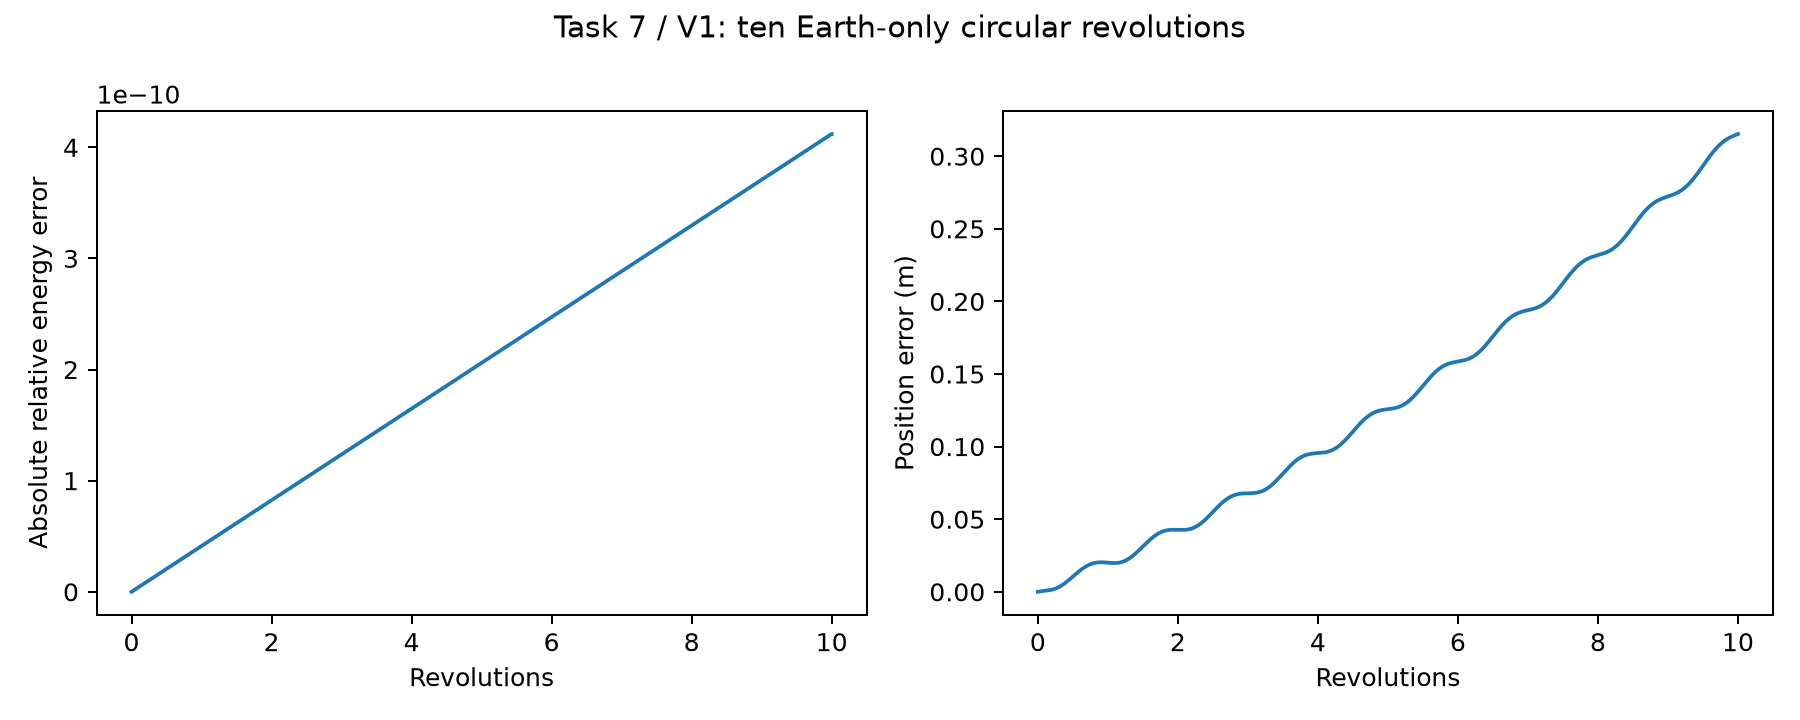

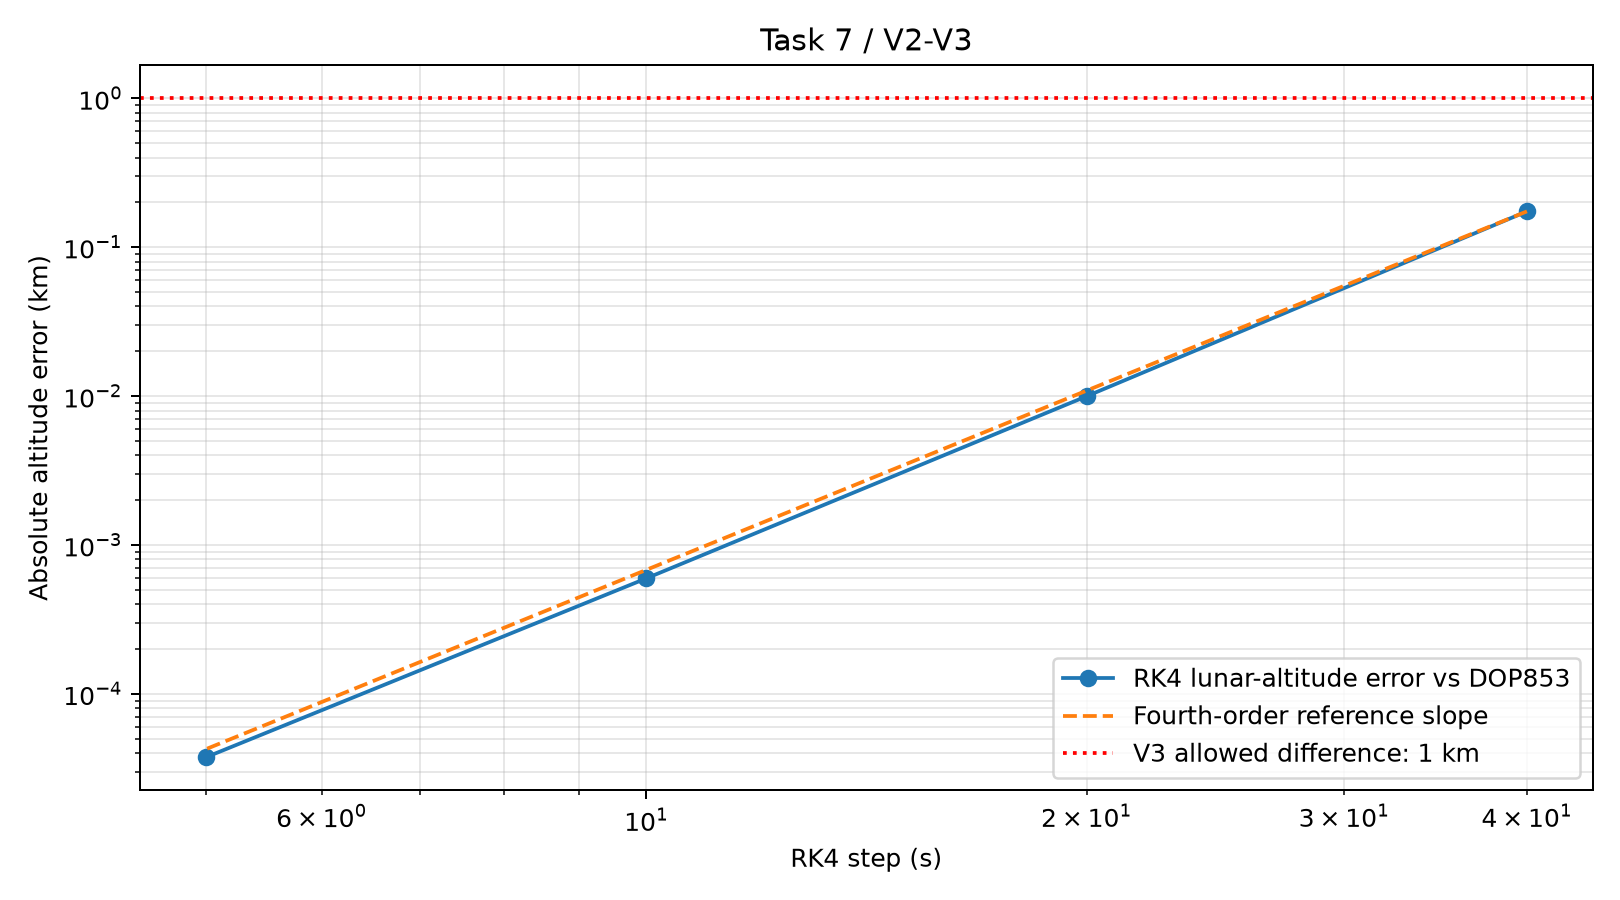

In [13]:
def two_body_figure(directory, revolutions, relative_energy_error, position_error_km):
    """V1: both error histories required by Section 5.4."""
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(revolutions, relative_energy_error)
    axes[0].set(xlabel='Revolutions', ylabel='Absolute relative energy error')
    axes[1].plot(revolutions, 1000*position_error_km)
    axes[1].set(xlabel='Revolutions', ylabel='Position error (m)')
    figure.suptitle('Task 7 / V1: ten Earth-only circular revolutions')
    save_figure(figure, directory, 'task7_v1_two_body.png')


def convergence_figure(directory, rows):
    """V2-V3: fourth-order convergence and the required 1 km cross-check bound."""
    steps = np.array([row['step_s'] for row in rows])
    errors = np.array([row['error_against_reference_km'] for row in rows])
    figure, axis = plt.subplots(figsize=(9, 5))
    axis.loglog(steps, errors, 'o-', label='RK4 lunar-altitude error vs DOP853')
    axis.loglog(steps, errors[0]*(steps/steps[0])**4, '--', label='Fourth-order reference slope')
    axis.axhline(1.0, linestyle=':', color='red', label='V3 allowed difference: 1 km')
    axis.set(xlabel='RK4 step (s)', ylabel='Absolute altitude error (km)', title='Task 7 / V2-V3')
    axis.grid(True, which='both', alpha=0.3)
    axis.legend()
    save_figure(figure, directory, 'task7_v2_v3_convergence.png')

def task_7_verification(settings, directory, delta_v_m_s, phase_rad, encounter):
    """Task 7: complete the three verification tests in Section 5.4."""
    # V1: turn off BOTH lunar acceleration terms and propagate ten Earth orbits.
    circular_initial = parking_state(settings)
    radius = np.linalg.norm(circular_initial[:2])
    angular_speed = np.sqrt(MU_EARTH/radius**3)
    period = 2*np.pi/angular_speed
    derivative = lambda t, y: coast_derivative(t, y, phase_rad, include_moon=False)
    times, states = rk4(derivative, circular_initial, 0.0, 10*period, settings.rk4_step_s)
    analytic_position = radius*np.column_stack((np.cos(angular_speed*times), np.sin(angular_speed*times)))
    position_error = np.linalg.norm(states[:, :2]-analytic_position, axis=1)
    energy = np.sum(states[:, 2:4]**2, axis=1)/2-MU_EARTH/np.linalg.norm(states[:, :2], axis=1)
    exact_energy = -MU_EARTH/(2*radius)
    relative_energy_error = np.abs((energy-exact_energy)/exact_energy)
    two_body_figure(directory, times/period, relative_energy_error, position_error)

    # V2: same departure, four RK4 step sizes. Refine the event between steps.
    derivative = lambda t, y: coast_derivative(t, y, phase_rad)
    initial = departure_state(settings, delta_v_m_s)
    convergence = []
    for step_s in settings.convergence_steps_s:
        times, states = rk4(derivative, initial, 0.0, encounter.time_s+900.0, step_s)
        event_time, altitude = rk4_lunar_minimum(times, states, phase_rad, encounter.time_s)
        convergence.append({
            'step_s': step_s, 'lunar_altitude_km': altitude,
            'time_to_closest_approach_h': event_time/HOUR,
            'error_against_reference_km': abs(altitude-encounter.altitude_km),
            'altitude_change_on_halving_km': None, 'observed_order': None,
        })
    for coarse, fine in zip(convergence[:-1], convergence[1:]):
        coarse['altitude_change_on_halving_km'] = fine['lunar_altitude_km']-coarse['lunar_altitude_km']
        coarse['observed_order'] = float(np.log(coarse['error_against_reference_km']/fine['error_against_reference_km'])
                                         / np.log(coarse['step_s']/fine['step_s']))

    # V3: the production RK4 step must agree with the library result within 1 km.
    production = next(row for row in convergence if row['step_s']==settings.rk4_step_s)
    v3_pass = production['error_against_reference_km'] < 1.0
    orders = [row['observed_order'] for row in convergence[:-1]]
    if not v3_pass:
        raise RuntimeError('V3 failed: RK4 altitude differs from reference by >=1 km')
    if not all(3.5 < order < 4.5 for order in orders):
        raise RuntimeError(f'V2 did not demonstrate approximately fourth order: {orders}')
    convergence_figure(directory, convergence)
    write_csv(directory/'task7_convergence.csv', convergence)
    print('Task 7: V1 complete; V2 orders='+', '.join(f'{p:.3f}' for p in orders))
    print(f'        V3 difference={production["error_against_reference_km"]*1000:.4f} m (<1000 m).')
    return {
        'V1_maximum_position_error_km': float(position_error.max()),
        'V1_maximum_relative_energy_error': float(relative_energy_error.max()),
        'V2_convergence': convergence, 'V3_pass': v3_pass,
    }

verification = task_7_verification(settings, OUTPUT, delta_v_m_s, phase_rad, baseline)
display_table([{
    'V1 max position error (m)': verification['V1_maximum_position_error_km']*1000,
    'V1 max relative energy error': verification['V1_maximum_relative_energy_error'],
    'V3 passed': verification['V3_pass'],
}])
display_table(verification['V2_convergence'])
show_figures('task7_v1_two_body.png', 'task7_v2_v3_convergence.png')


### How to interpret the verification output
A small error is useful, but the convergence trend is stronger evidence that the integrator is working. Look for decreasing altitude error and orders close to four. V1 checks units, force direction, and long-term circular-orbit integration. V3 checks the lunar result against a separate integration algorithm. Frame inversion and Jacobi conservation add consistency checks for the reference-frame treatment.

No numerical test establishes that this simplified model includes all real mission physics. Solar gravity, three-dimensional geometry, finite burns, and lunar gravity harmonics remain outside its scope.


## Task 8: sensitivity to departure errors

Starting from the solved departure, vary **one input at a time**:

1. TLI magnitude −1 m/s and +1 m/s.
2. Initial Moon phase −0.5° and +0.5°.

Each disturbed case keeps the other input fixed and **does not retarget**. Otherwise the optimizer would remove the disturbance being measured.

The output gives the change in lunar altitude relative to nominal. If a disturbed trajectory hits the Moon, it stops at the surface and is marked `moon_impact`. Its minimum physical altitude is zero, and its event time is surface-contact time, not an underground periapsis. The graph marks these cases in red.

Small departure errors accumulate during a multi-day coast and change encounter geometry. Tracking and midcourse corrections help keep arrival altitude and capture conditions within bounds.


Task 8: sensitivity complete. Small departure errors accumulate over a multi-day coast and change lunar encounter geometry. Tracking and midcourse corrections are needed to control arrival altitude and capture conditions. Impact cases stop at altitude zero; their event time is contact time, not an underground periapsis.


| case | TLI_error_m_s | phase_error_deg | event | lunar_altitude_km | altitude_change_km | time_to_event_h |
| --- | --- | --- | --- | --- | --- | --- |
| Nominal | 0 | 0 | closest_approach | 110 | 0 | 72 |
| TLI -1 m/s | -1 | 0 | moon_impact | 0 | -110 | 72.092295 |
| TLI +1 m/s | 1 | 0 | closest_approach | 824.30198 | 714.30198 | 71.7470927 |
| Phase -0.5 deg | 0 | -0.5 | closest_approach | 1727.61219 | 1617.61219 | 72.9236781 |
| Phase +0.5 deg | 0 | 0.5 | moon_impact | 0 | -110 | 70.9256492 |

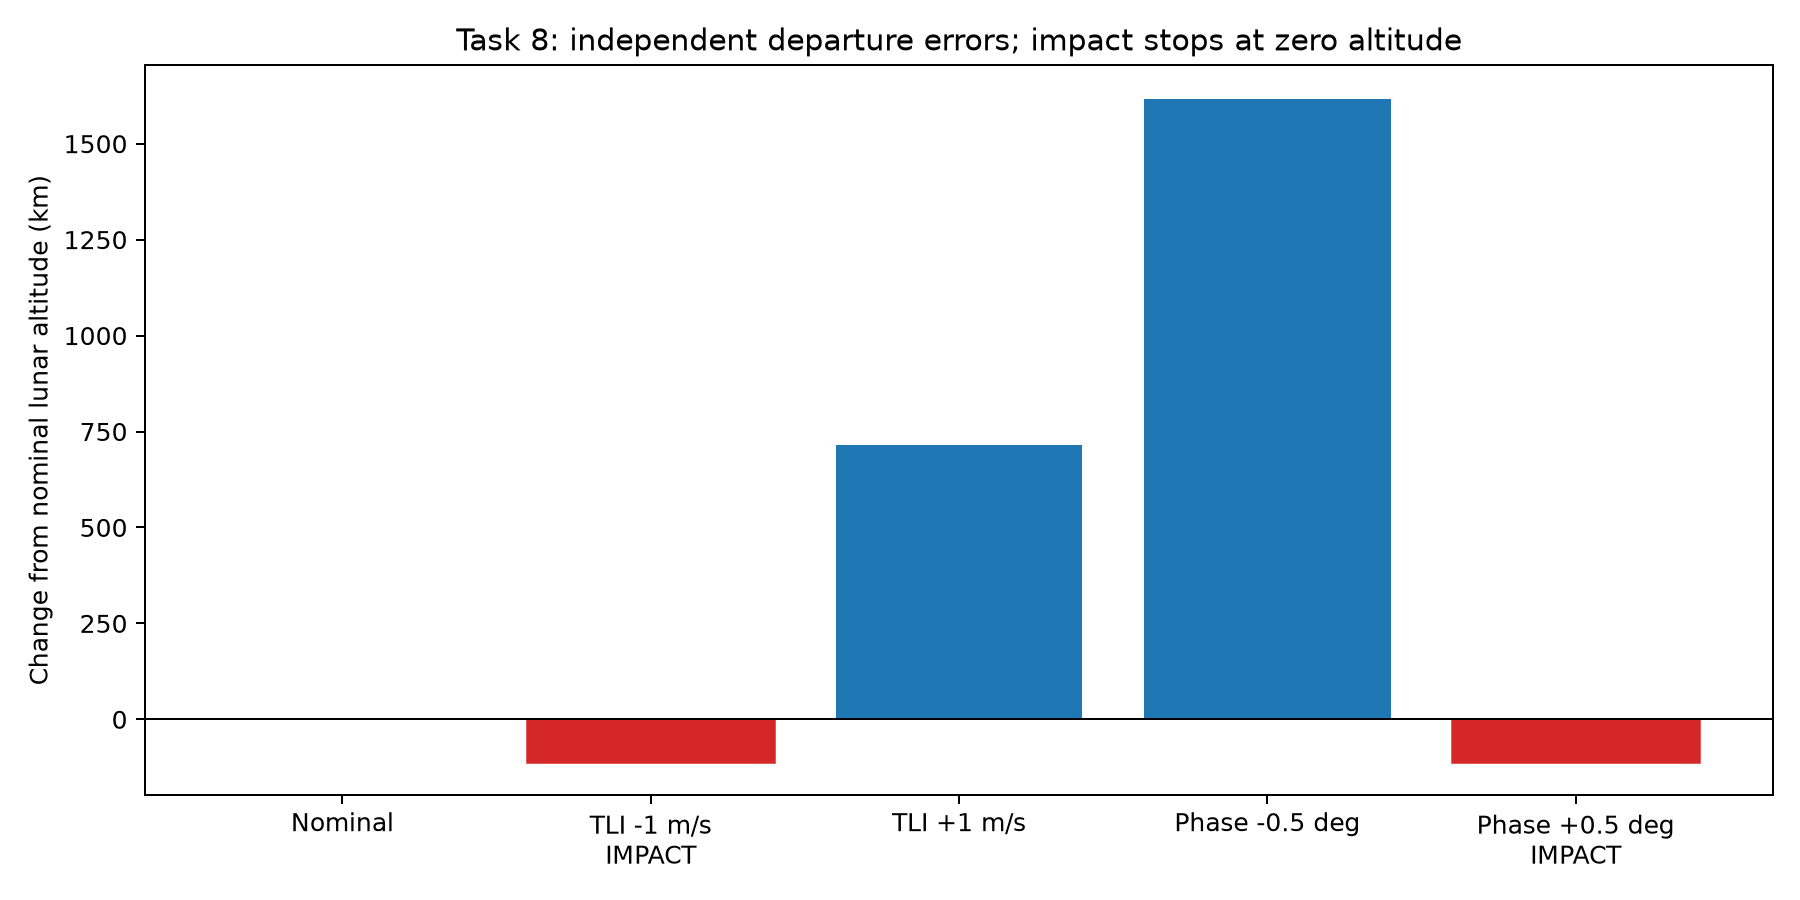

In [14]:
def sensitivity_figure(directory, rows):
    """Task 8: clearly identify surface-impact cases instead of hiding them."""
    labels = [row['case'] + ('\nIMPACT' if row['event']=='moon_impact' else '') for row in rows]
    changes = [row['altitude_change_km'] for row in rows]
    figure, axis = plt.subplots(figsize=(10, 5))
    bars = axis.bar(labels, changes)
    for bar, row in zip(bars, rows):
        if row['event']=='moon_impact':
            bar.set_color('tab:red')
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set(ylabel='Change from nominal lunar altitude (km)',
             title='Task 8: independent departure errors; impact stops at zero altitude')
    save_figure(figure, directory, 'task8_sensitivity.png')

def task_8_sensitivity(settings, directory, delta_v_m_s, phase_rad, nominal):
    """Task 8: independent +/-1 m/s TLI and +/-0.5 degree phase perturbations.

    Do NOT rerun the targeting optimizer for these cases: that would remove the
    errors we are trying to measure. Impact cases stop at the lunar surface.
    Their reported zero altitude is physical surface contact, not periapsis.
    """
    cases = [('Nominal', 0.0, 0.0), ('TLI -1 m/s', -1.0, 0.0),
             ('TLI +1 m/s', 1.0, 0.0), ('Phase -0.5 deg', 0.0, -0.5),
             ('Phase +0.5 deg', 0.0, 0.5)]
    rows = []
    for name, delta_error_m_s, phase_error_deg in cases:
        encounter = integrate_to_encounter(settings, delta_v_m_s+delta_error_m_s,
                                           phase_rad+np.deg2rad(phase_error_deg))
        if encounter.event == 'earth_impact':
            raise RuntimeError('Perturbation returned to Earth before lunar encounter')
        rows.append({
            'case': name, 'TLI_error_m_s': delta_error_m_s, 'phase_error_deg': phase_error_deg,
            'event': encounter.event, 'lunar_altitude_km': encounter.altitude_km,
            'altitude_change_km': encounter.altitude_km-nominal.altitude_km,
            'time_to_event_h': encounter.time_s/HOUR,
        })
    write_csv(directory/'task8_sensitivity.csv', rows)
    sensitivity_figure(directory, rows)
    explanation = (
        'Small departure errors accumulate over a multi-day coast and change lunar encounter geometry. '
        'Tracking and midcourse corrections are needed to control arrival altitude and capture conditions. '
        'Impact cases stop at altitude zero; their event time is contact time, not an underground periapsis.'
    )
    print('Task 8: sensitivity complete. '+explanation)
    return {'cases': rows, 'interpretation': explanation}

sensitivity = task_8_sensitivity(settings, OUTPUT, delta_v_m_s, phase_rad, baseline)
display_table(sensitivity['cases'])
show_figures('task8_sensitivity.png')


## Task 9 / Scenario A: Apollo 11 lunar orbit insertion

**Tasks 1–8 are complete.** We now add the assigned scenario to the same baseline arrival state. Scenario A asks for insertion into a lunar orbit near 110 km and a comparison with published mission values.

At lunar closest approach, translate into the Moon-centered frame:
\[
\boldsymbol\rho=\mathbf r-\mathbf r_M,\qquad
\mathbf v_{rel}=\mathbf v-\mathbf v_M,\qquad r_p=\|\boldsymbol\rho\|.
\]
Let \(\hat{\mathbf t}\) be a tangent unit vector in the arrival direction. Set the post-burn relative velocity to
\[
\mathbf v_{rel,after}=\sqrt{\mu_M/r_p}\,\hat{\mathbf t},
\qquad
\Delta\mathbf v_{LOI}=\mathbf v_{rel,after}-\mathbf v_{rel,before}.
\]
The impulse is retrograde for this arrival. In ECI, the new velocity is \(\mathbf v_M+\mathbf v_{rel,after}\). The same velocity increment applies in the two parallel-axis frames.

We check that the initial Moon-relative specific energy is negative and the osculating eccentricity is near zero. The eccentricity vector is
\[
\mathbf e=\frac{(v_{rel}^2-\mu_M/r_p)\boldsymbol\rho
-(\boldsymbol\rho\cdot\mathbf v_{rel})\mathbf v_{rel}}{\mu_M}.
\]
For a circular lunar two-body orbit, its period is \(P=2\pi\sqrt{r_p^3/\mu_M}\).

Finally, propagate 24 hours using the **same Earth–Moon force model**. An initially circular *osculating* orbit is an instantaneous two-body description. Earth tides cause a small altitude variation during the subsequent three-body motion.


Task 9 / A: LOI=899.797502 m/s, captured altitude 109.934289 to 110.010907 km over 24 h.


| Quantity | Value | Unit |
| --- | --- | --- |
| LOI delta-v | 899.797502 | m/s |
| Moon-relative speed before LOI | 2.52887453 | km/s |
| Moon-relative speed after LOI | 1.62907703 | km/s |
| Initial osculating eccentricity | 1.67335075e-16 | - |
| Initial lunar period | 1.97923193 | h |
| Minimum altitude during capture coast | 109.934289 | km |
| Maximum altitude during capture coast | 110.010907 | km |
| LOI propellant (assumed mass/Isp) | 5308.69759 | kg |

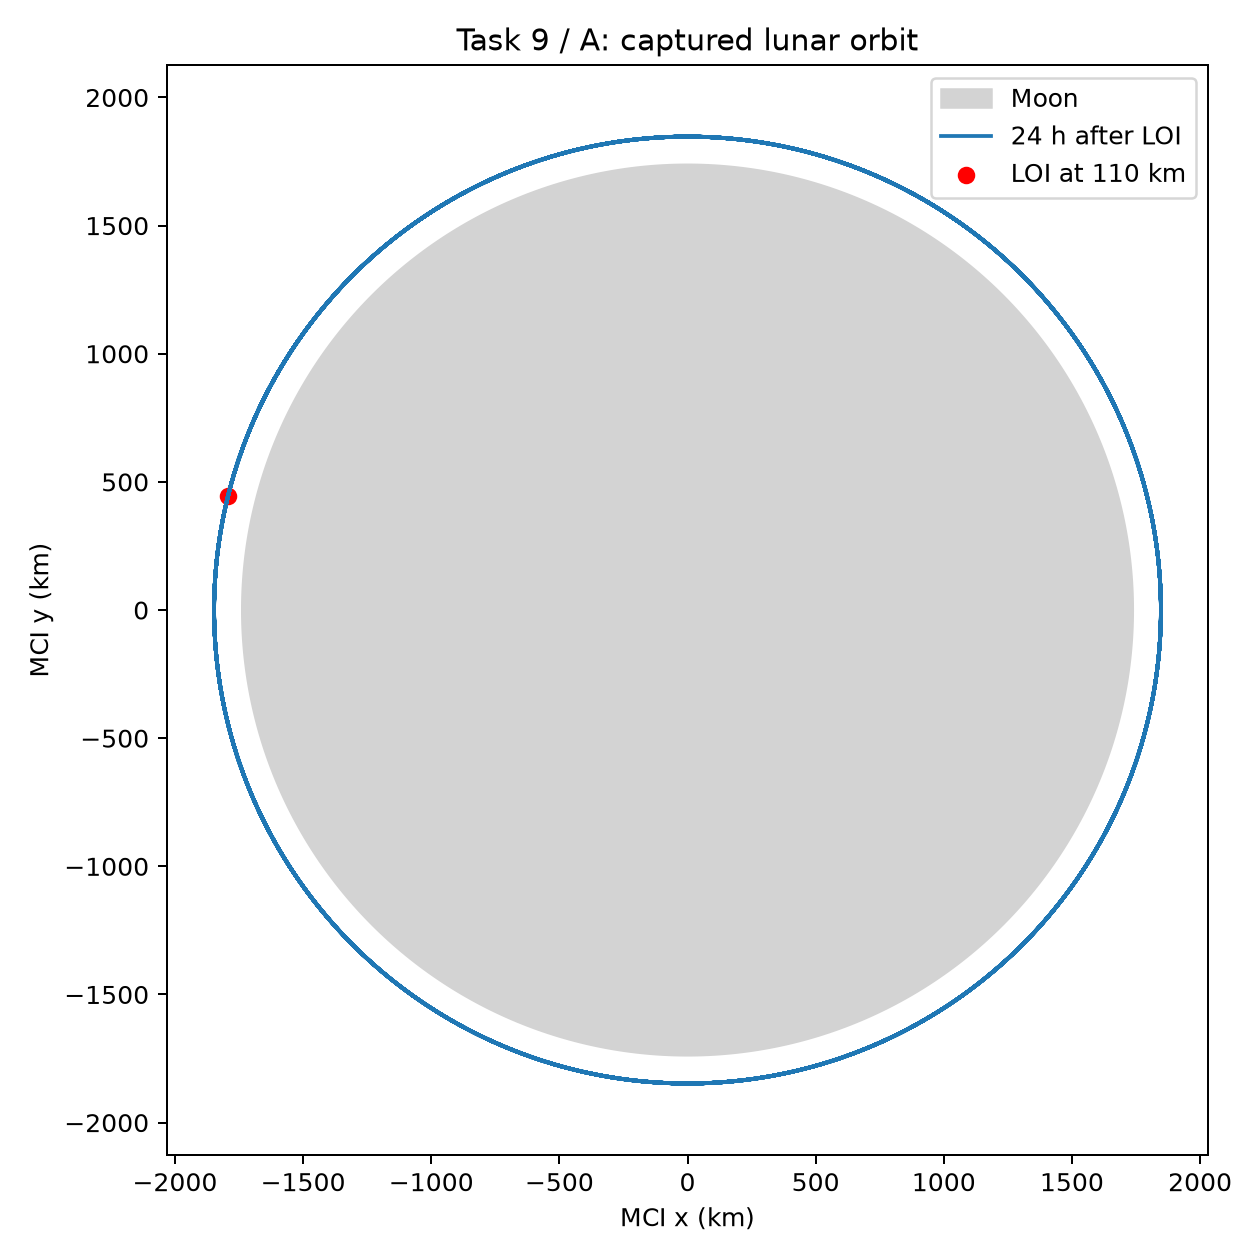

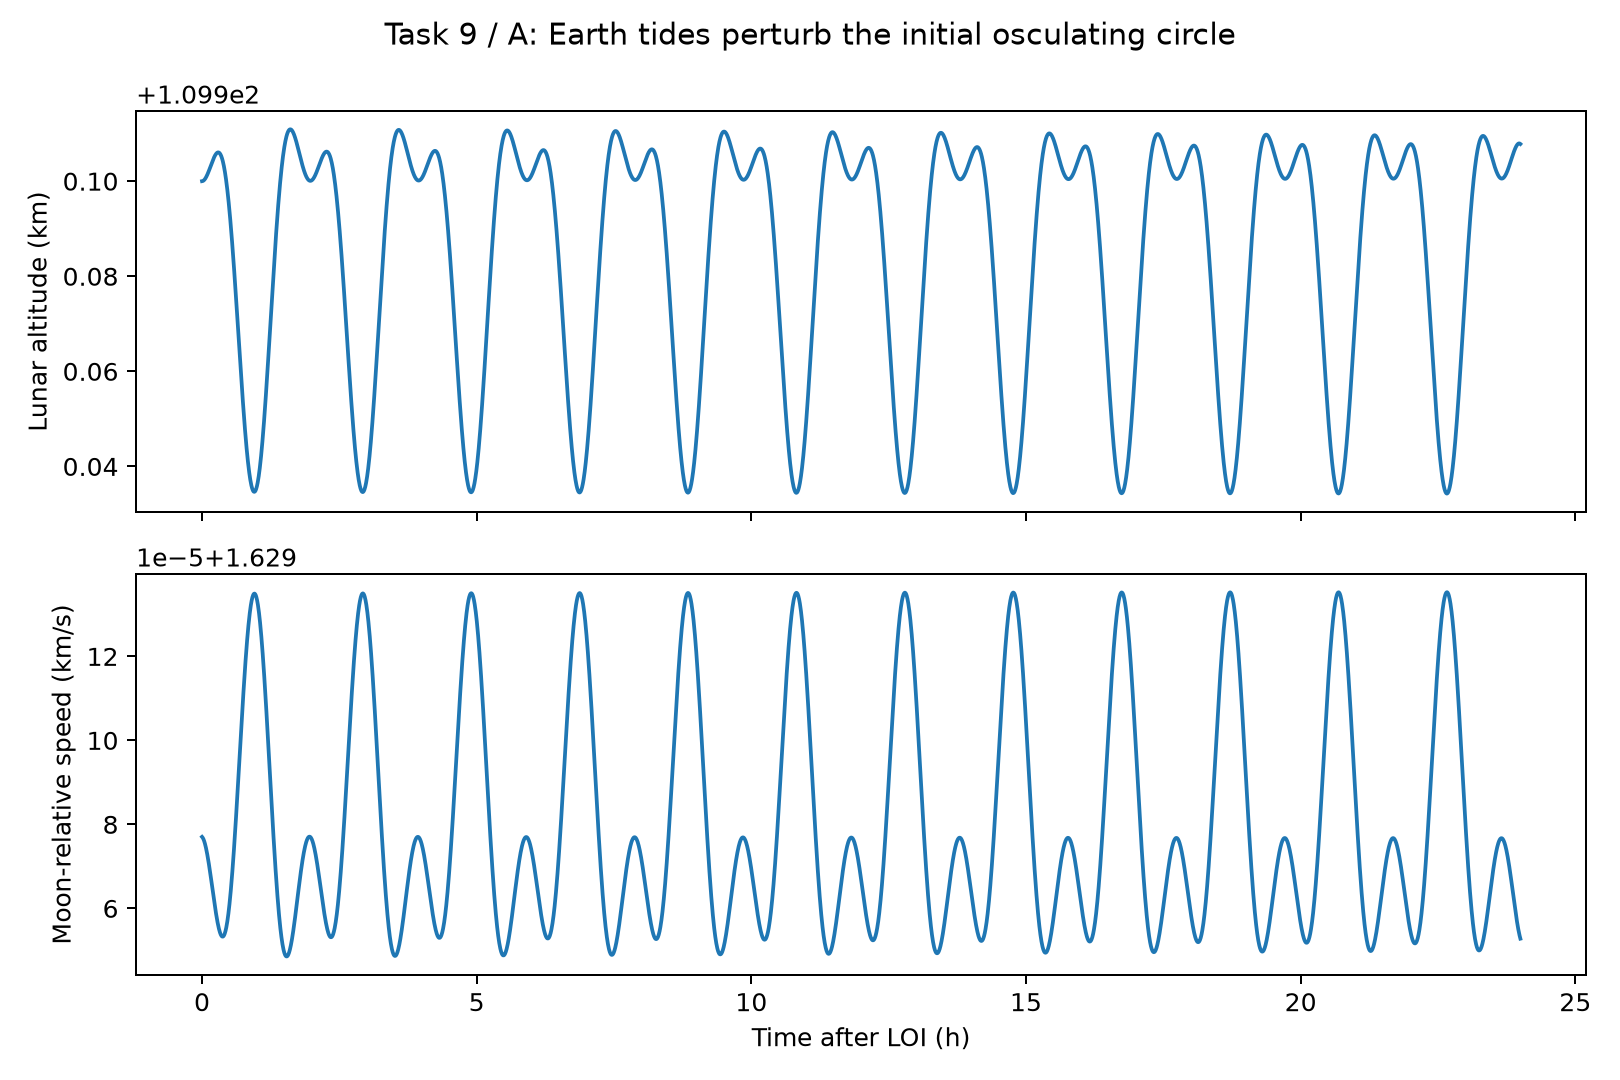

In [15]:
def capture_figures(directory, times, states, phase_rad):
    """Task 9 / Scenario A: show the captured orbit and its perturbed altitude."""
    relative_position, relative_velocity = to_moon_frame(times, states, phase_rad)
    figure, axis = plt.subplots(figsize=(7, 7))
    angle = np.linspace(0, 2*np.pi, 500)
    axis.fill(R_MOON*np.cos(angle), R_MOON*np.sin(angle), color='lightgray', label='Moon')
    axis.plot(relative_position[:, 0], relative_position[:, 1], label='24 h after LOI')
    axis.scatter(*relative_position[0], color='red', label='LOI at 110 km')
    axis.set(xlabel='MCI x (km)', ylabel='MCI y (km)', title='Task 9 / A: captured lunar orbit')
    axis.axis('equal')
    axis.legend()
    save_figure(figure, directory, 'task9A_lunar_orbit.png')

    figure, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    elapsed = (times-times[0])/HOUR
    axes[0].plot(elapsed, np.linalg.norm(relative_position, axis=1)-R_MOON)
    axes[0].set_ylabel('Lunar altitude (km)')
    axes[1].plot(elapsed, np.linalg.norm(relative_velocity, axis=1))
    axes[1].set(xlabel='Time after LOI (h)', ylabel='Moon-relative speed (km/s)')
    figure.suptitle('Task 9 / A: Earth tides perturb the initial osculating circle')
    save_figure(figure, directory, 'task9A_capture_history.png')

def task_9_scenario_a(settings, directory, nominal, phase_rad):
    """Task 9 / Scenario A: Apollo 11 style insertion into a ~110 km lunar orbit.

    At periapsis, Moon-relative radial velocity is zero. A retrograde impulse
    sets the tangential speed to sqrt(muM/rp), making an initially circular
    osculating lunar orbit. Restore the Moon's velocity before ECI propagation.
    We retain Earth gravity and the indirect term for a 24 h captured coast.
    """
    position, velocity = to_moon_frame(nominal.time_s, nominal.state, phase_rad)
    radius = np.linalg.norm(position)
    radial_unit = position/radius
    tangent = velocity-np.dot(velocity, radial_unit)*radial_unit
    tangent /= np.linalg.norm(tangent)
    circular_velocity = np.sqrt(MU_MOON/radius)*tangent
    impulse = circular_velocity-velocity
    delta_v_m_s = 1000*np.linalg.norm(impulse)
    after = apply_impulse(nominal.state, impulse, settings.loi_specific_impulse_s)

    end_s = nominal.time_s+settings.captured_orbit_duration_h*HOUR
    capture = reference_coast(settings, after, phase_rad, nominal.time_s, end_s)
    times = np.linspace(nominal.time_s, end_s, 5000)
    states = capture.sol(times).T
    relative_position, _ = to_moon_frame(times, states, phase_rad)
    altitudes = np.linalg.norm(relative_position, axis=1)-R_MOON
    specific_energy = np.dot(circular_velocity, circular_velocity)/2-MU_MOON/radius
    eccentricity_vector = ((np.dot(circular_velocity, circular_velocity)-MU_MOON/radius)*position
                           - np.dot(position, circular_velocity)*circular_velocity)/MU_MOON
    eccentricity = float(np.linalg.norm(eccentricity_vector))
    if specific_energy >= 0 or eccentricity > 1e-9 or altitudes.min() <= 0:
        raise RuntimeError('Scenario A did not produce a safe, initially circular bound orbit')

    # Published values: NASA Apollo 11 Mission Report, Nov. 1969, Table 7-V.
    # Source: https://www.nasa.gov/wp-content/uploads/static/apollo50th/pdf/A11_MissionReport.pdf
    # 1 international foot = 0.3048 m. The historical FIRST burn entered an
    # ellipse; a SECOND burn changed the orbit. Our one-burn circular target
    # therefore differs from either individual historical burn.
    historical_first_m_s = 2917.5*0.3048
    historical_second_m_s = 158.8*0.3048
    comparison = {
        'source': 'NASA Apollo 11 Mission Report, November 1969, Table 7-V',
        'source_url': 'https://www.nasa.gov/wp-content/uploads/static/apollo50th/pdf/A11_MissionReport.pdf',
        'first_capture_burn_m_s': historical_first_m_s,
        'later_circularization_burn_m_s': historical_second_m_s,
        'sum_of_historical_burn_magnitudes_m_s': historical_first_m_s+historical_second_m_s,
        'model_minus_historical_first_m_s': float(delta_v_m_s-historical_first_m_s),
        'model_minus_historical_sum_m_s': float(delta_v_m_s-historical_first_m_s-historical_second_m_s),
        'interpretation': 'Different arrival states, target orbits, and impulsive versus finite burns prevent an exact historical match.',
    }
    capture_figures(directory, times, states, phase_rad)
    write_csv(directory/'task9A_capture_history.csv', [
        dict(time_since_TLI_s=float(t), time_since_LOI_s=float(t-times[0]),
             x_km=float(y[0]), y_km=float(y[1]), vx_km_s=float(y[2]),
             vy_km_s=float(y[3]), mass_kg=float(y[4]), lunar_altitude_km=float(alt))
        for t, y, alt in zip(times, states, altitudes)
    ])
    print(f'Task 9 / A: LOI={delta_v_m_s:.6f} m/s, captured altitude '
          f'{altitudes.min():.6f} to {altitudes.max():.6f} km over 24 h.')
    return {
        'scenario': 'A - Apollo 11', 'LOI_delta_v_m_s': float(delta_v_m_s),
        'LOI_vector_ECI_km_s': impulse.tolist(), 'state_after_LOI': after.tolist(),
        'LOI_propellant_kg': float(nominal.state[4]-after[4]),
        'pre_LOI_Moon_relative_speed_km_s': float(np.linalg.norm(velocity)),
        'post_LOI_Moon_relative_speed_km_s': float(np.linalg.norm(circular_velocity)),
        'initial_lunar_eccentricity': eccentricity,
        'initial_lunar_specific_energy_km2_s2': float(specific_energy),
        'initial_lunar_period_h': float(2*np.pi*np.sqrt(radius**3/MU_MOON)/HOUR),
        'capture_duration_h': settings.captured_orbit_duration_h,
        'minimum_captured_altitude_km': float(altitudes.min()),
        'maximum_captured_altitude_km': float(altitudes.max()),
        'historical_comparison': comparison,
    }

scenario = task_9_scenario_a(settings, OUTPUT, baseline, phase_rad)
display_table([
    {'Quantity': 'LOI delta-v', 'Value': scenario['LOI_delta_v_m_s'], 'Unit': 'm/s'},
    {'Quantity': 'Moon-relative speed before LOI', 'Value': scenario['pre_LOI_Moon_relative_speed_km_s'], 'Unit': 'km/s'},
    {'Quantity': 'Moon-relative speed after LOI', 'Value': scenario['post_LOI_Moon_relative_speed_km_s'], 'Unit': 'km/s'},
    {'Quantity': 'Initial osculating eccentricity', 'Value': scenario['initial_lunar_eccentricity'], 'Unit': '-'},
    {'Quantity': 'Initial lunar period', 'Value': scenario['initial_lunar_period_h'], 'Unit': 'h'},
    {'Quantity': 'Minimum altitude during capture coast', 'Value': scenario['minimum_captured_altitude_km'], 'Unit': 'km'},
    {'Quantity': 'Maximum altitude during capture coast', 'Value': scenario['maximum_captured_altitude_km'], 'Unit': 'km'},
    {'Quantity': 'LOI propellant (assumed mass/Isp)', 'Value': scenario['LOI_propellant_kg'], 'Unit': 'kg'},
])
show_figures('task9A_lunar_orbit.png', 'task9A_capture_history.png')


### Scenario A: comparison with published Apollo 11 maneuvers

The numerical comparison below uses NASA's [Apollo 11 Mission Report, November 1969, Table 7-V](https://www.nasa.gov/wp-content/uploads/static/apollo50th/pdf/A11_MissionReport.pdf).

The actual mission first captured into an elliptical orbit, then changed that orbit with a later maneuver. Our model instead targets a 110 km circle directly with one instantaneous burn. We therefore compare both the first published capture and the scalar sum of the two maneuver magnitudes. The sum is a delta-v budget, not a single inertial velocity vector.

Differences reflect the arrival state, orbit targets, and impulsive versus finite-burn treatment. They do not demonstrate that this design improves on the historical flight. Historical ground elapsed time starts at launch; this notebook's time starts at TLI.


In [16]:
comparison = scenario['historical_comparison']
display_table([
    {'Maneuver / comparison': 'Model: direct circular LOI', 'Delta-v (m/s)': scenario['LOI_delta_v_m_s']},
    {'Maneuver / comparison': 'Published: first capture', 'Delta-v (m/s)': comparison['first_capture_burn_m_s']},
    {'Maneuver / comparison': 'Published: later circularization', 'Delta-v (m/s)': comparison['later_circularization_burn_m_s']},
    {'Maneuver / comparison': 'Published: sum of magnitudes', 'Delta-v (m/s)': comparison['sum_of_historical_burn_magnitudes_m_s']},
    {'Maneuver / comparison': 'Model minus published first capture', 'Delta-v (m/s)': comparison['model_minus_historical_first_m_s']},
    {'Maneuver / comparison': 'Model minus published sum', 'Delta-v (m/s)': comparison['model_minus_historical_sum_m_s']},
])


| Maneuver / comparison | Delta-v (m/s) |
| --- | --- |
| Model: direct circular LOI | 899.797502 |
| Published: first capture | 889.254 |
| Published: later circularization | 48.40224 |
| Published: sum of magnitudes | 937.65624 |
| Model minus published first capture | 10.5435023 |
| Model minus published sum | -37.8587377 |

## Required class summary and numerical exports

This is the Section 5.5 summary row for the common outbound baseline. TLI propellant is listed here; LOI propellant is reported separately above. Both depend on the explicitly assumed masses and specific impulses.

The final cell saves the row and a complete machine-readable summary. All numerical outputs can be reproduced by restarting the kernel and running the notebook from the top. The earlier `.py` project is not required.


In [17]:
class_summary = {
    'Parking altitude (km)': settings.parking_altitude_km,
    'TLI delta-v (m/s)': delta_v_m_s,
    'TLI propellant, assumed inputs (kg)': initial_summary['TLI_propellant_kg'],
    'Lunar time of flight (h)': baseline.time_s/HOUR,
    'Lunar closest altitude (km)': baseline.altitude_km,
    'Integrator': 'DOP853 reference; own RK4 cross-check',
    'RK4 step (s)': settings.rk4_step_s,
    'DOP853 rtol': settings.reference_rtol,
}
write_csv(OUTPUT/'class_summary.csv', [class_summary])
summary = {
    'scope': 'Common Tasks 1-8 plus Task 9 / Scenario A (Apollo 11)',
    'settings': asdict(settings),
    'task2_initial_conditions': initial_summary,
    'task3_frame_checks': frame_checks,
    'task5_baseline': {'lunar_altitude_km': baseline.altitude_km, 'time_of_flight_h': baseline.time_s/HOUR},
    'task7_verification': verification,
    'task8_sensitivity': sensitivity,
    'task9_scenario_A': scenario,
    'environment': {'python': platform.python_version(), 'numpy': np.__version__, 'scipy': scipy.__version__},
    'runtime_s': time.perf_counter()-run_started,
}
(OUTPUT/'summary.json').write_text(json.dumps(summary, indent=2))
display_table([class_summary])
print(f"All tasks executed. V3 passed: {verification['V3_pass']}.")
print(f"Measured notebook computation time: {summary['runtime_s']:.1f} seconds.")
print(f'CSV, JSON, and PNG outputs: {OUTPUT}')


| Parking altitude (km) | TLI delta-v (m/s) | TLI propellant, assumed inputs (kg) | Lunar time of flight (h) | Lunar closest altitude (km) | Integrator | RK4 step (s) | DOP853 rtol |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 185 | 3156.24191 | 24049.1325 | 72 | 110 | DOP853 reference; own RK4 cross-check | 10 | 1e-12 |

All tasks executed. V3 passed: True.
Measured notebook computation time: 78.5 seconds.
CSV, JSON, and PNG outputs: c:\Users\ruthv\Documents\MEC568-Project\mec568_notebook_results


## Scope and sources

- Assignment requirements and constants: supplied MEC 568 *Spacecraft Trajectory Calculation from Earth to Moon* handout, Sections 4–6.
- Apollo 11 maneuver comparison: NASA *Apollo 11 Mission Report*, November 1969, Table 7-V, linked in Scenario A above.
- This notebook uses circular planar Earth–Moon motion, spherical gravity, and impulsive burns. It does not include the optional solar-gravity, real-ephemeris, or J2 extensions.
- Mass and engine inputs are illustrative assumptions. The solved departure and capture are idealized designs, not a replay of historical state vectors.
- AI assisted code development, explanations, and verification. Review the calculations and be able to explain them; the handout requires disclosure in any eventual presentation.
